# WLadaLASSO — LASSO-type penalties for covariate selection and forecasting (Google Colab notebook)

**Status: the outputs saved in this notebook come from one `PROFILE = "quick_check"` run (a short test of the whole pipeline; two of the three equity data versions, because the original 2005 file was not available for that run). They are not results. For the study itself set `PROFILE = "standard"` (and `"full"` for the gamma-by-BIC runs) in section 8.** It contains no results and no output cells. Every number you see after running it comes from your own run.

**What this project is.** We reproduce and extend Konzen & Ziegelmann (2016, *Journal of Forecasting*). They propose WLadaLASSO, an adaptive LASSO whose penalty also grows with the lag length.
In this notebook we compare four methods — **LASSO, adaLASSO, WLadaLASSO and Ext1** — in a Monte Carlo study and in two forecasting applications (equity premium and FRED-MD monthly inflation).

**You need only this notebook and one data file, `datasets.zip`.** All code is inside the notebook (section 6). You do not need to know Python: follow the steps below.

**Cell labels.** Every section title carries one label that tells you what kind of cell it is:
**[SETUP]** installs and prepares things · **[CONFIGURE]** settings you may change · **[RUN]** starts an experiment (can take hours) · **[RESULTS]** shows or saves results (fast, reads saved work only) · **[CODE]** definitions that only need to be run once.

## How to run this notebook — step by step

A Colab notebook is a document made of text cells (like this one) and code cells. Press the ▶ button at the left of a code cell to run it. Cells should be run from top to bottom.

| Step | What to do | Where |
|---|---|---|
| **1. Open in Colab** | Go to colab.research.google.com → *File → Upload notebook* → choose `WLadaLASSO_Standalone.ipynb`. | — |
| **2. Upload the data** | Run the cell in section 3. A file dialog appears: choose `datasets.zip`. (If `datasets.zip` is already in the *Files* panel on the left, no dialog appears.) | Section 3 |
| **3. Run setup and data checks** | Run sections 2 → 7 in order: install packages, extract and validate the data, define the methods, run the unit tests. **Expected:** the table in section 4 shows four datasets with `found = True` and all checks `ok = True`; section 7 ends with `ALL TESTS PASSED`. No experiment runs in these sections. | Sections 2–7 |
| **4. Look at the configuration** | Section 8. Most users change only **four things**: `PROFILE`, the `RUN` switches, `MAKE_VISUALISATIONS` and `USE_DRIVE`. Everything under "advanced settings" can stay as it is. Run both cells of section 8; the printed summary shows what will be run. | Section 8 |
| **5. Run experiments** | Set the switch of an experiment to `True` in section 8 (run that cell again), then run the cells of that experiment's section (9–13). Each experiment saves its results and prints tables. | Sections 9–13 |
| **6. Run only one experiment** | Keep all other switches `False`. Example: only the equity premium → `RUN["equity"] = True`, then run section 10. Sections of switched-off experiments print a `Skipped` message and do nothing. | Section 8 + its section |
| **7. Figures on or off** | `MAKE_VISUALISATIONS = True` draws the Monte Carlo boxplot figure (12 panels) when the Monte Carlo results are shown; `False` skips it. The figure only reads finished results: it cannot change any result. | Section 8, 9.3, 15 |
| **8. Where results are stored** | With `USE_DRIVE = False` results are written to Colab's temporary disk and **disappear when the runtime is recycled**. With `USE_DRIVE = True` the notebook mounts your Google Drive and creates the folder `My Drive/WLadaLASSO_results/` by itself (you do not create any folder). Results and checkpoints are kept there. | Section 8 |
| **9. Resume after a disconnection** | Reconnect, run sections 2–8 again **with the same settings**, then run the same experiment cell. Finished work (saved in `checkpoints/`) is loaded, not recomputed; only the missing part is calculated. Use `USE_DRIVE = True` if you want this to work after the runtime has been deleted. | Sections 2–8, then the experiment |
| **10. Find the final results** | Tables are shown in the notebook after each experiment. Complete results are in the results folder (structure below). Section 16 writes a summary and a ZIP file for download. | Section 16 |

### What does *Runtime → Run all* do? Is it appropriate?
*Run all* runs every code cell from top to bottom. With the default settings this is **safe**: all experiment switches are `False`, so it only does the setup, shows the upload dialog (and waits for you), runs the unit tests and prints `Skipped` for each experiment.
It is **not appropriate after you have switched experiments on**: it would then start all of them one after another, which can take many hours, and Colab may disconnect. For real runs we suggest to run the cells one section at a time.

### Results folder (created automatically)
```
results/                       (on Drive: My Drive/WLadaLASSO_results/)
├── monte_carlo/
│   ├── standard/<run id>/            replication-level results of the main Monte Carlo (refit every 5 forecasts)
│   ├── gamma_robustness/<run id>/    robustness: gamma chosen by BIC
│   ├── summaries/<run id>/           summary tables and paired tests (CSV)
│   └── figures/<run id>/             the 12-panel boxplot figure (PNG and PDF)
├── equity_premium/{original_2005, current_crsp, current_index}/<run id>/   plus summaries/
├── fred_md/summaries/<run id>/
├── checkpoints/                      unfinished and finished pieces of work, used to resume (do not delete)
├── logs/run_log.txt                  what was started and finished, with times
├── run_registry.csv                  one line for every run started or finished
└── consolidated/<time stamp>/        final summary written by section 16
```
Every run folder contains `run_metadata.json` (experiment, settings, seed, grids, status *completed* or *incomplete*, times). The `<run id>` is the profile plus a code made from all settings that influence the numbers, so a run with different settings always gets a different folder and never overwrites an earlier one.

**Runtime warning.** The main Monte Carlo (12 scenarios × 1,000 replications) takes many hours on Colab's 2 cores and may need several sessions (see the work counter in section 8). The `quick_check` profile only tests that the notebook works; **its output is never a research result.**

## 1. Project introduction and research objectives

**Question.** Does penalising *distant* lags more heavily than recent ones (WLadaLASSO) help to select covariates and to forecast in high-dimensional time-series regressions, compared with LASSO and adaLASSO?

**The five final experiments in this notebook (each can be run alone):** (i) main Monte Carlo, 12 scenarios, 1,000 replications, γ = 1; (ii) γ-BIC Monte Carlo, 300 replications (BIC also chooses γ); (iii) main equity-premium forecasting, three data versions; (iv) γ-BIC equity-premium forecasting; (v) FRED-MD monthly inflation (section 11, model refitted at every origin). *Ext2 from earlier drafts was removed and is not part of this study.*

**Decisions fixed by the project specification:** 1,000 replications; the model is refitted every 5 forecasts in the main Monte Carlo; γ = 1 in the main design; BIC (not AIC) selects the penalty;
ρ ∈ {0.3, 0.9}, T ∈ {50, 500}, L ∈ {5, 10, 20}.

**Open decisions — flagged, not resolved:** (a) in the earlier study the equity-premium results did not reproduce the published Table X, and the cause is unknown.
This needs the approval of the project owner. Nothing in this notebook is tuned towards the paper.

## 2. Environment setup  **[SETUP]**
We install the few packages that Colab does not have (`xlrd` reads the original 2005 `.xls` file) and import everything that the code needs. **Run both cells. Expected output:** the Python and package versions.

In [1]:
import sys, subprocess, importlib.util
def _pip(pkg):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
for _mod, _pkg in [("xlrd", "xlrd>=2.0.1"), ("openpyxl", "openpyxl")]:
    if importlib.util.find_spec(_mod) is None:
        _pip(_pkg)

In [2]:
import os, io, re, sys, json, time, glob, shutil, hashlib, pickle, platform, tempfile, traceback, warnings, zipfile, itertools
import numpy as np
import pandas as pd
from scipy import stats
from scipy.signal import lfilter
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import lasso_path
from joblib import Parallel, delayed
import matplotlib.pyplot as plt

try:
    display                               # available in Colab / Jupyter
except NameError:
    display = print

IN_COLAB = "google.colab" in sys.modules
WORK = "/content/wlada_work" if IN_COLAB else os.path.abspath("wlada_work")     # local working directory (temporary on Colab)
os.makedirs(WORK, exist_ok=True)

VERSIONS = {m: getattr(__import__(m), "__version__", "n/a") for m in ("numpy", "scipy", "pandas", "sklearn", "joblib", "matplotlib", "openpyxl", "xlrd")
            if importlib.util.find_spec(m) is not None}
print("python", platform.python_version(), "| Colab:", IN_COLAB)
print(json.dumps(VERSIONS))

python 3.13.18 | Colab: False
{"numpy": "2.5.3", "scipy": "1.18.1", "pandas": "3.0.5", "sklearn": "1.9.1", "joblib": "1.6.0", "matplotlib": "3.11.2", "openpyxl": "3.1.5", "xlrd": "2.0.2"}


## 3. Dataset upload  **[SETUP]**
Run the next cell and **choose `datasets.zip`** in the file dialog. If `datasets.zip` is already in the Colab *Files* panel (folder `/content`), it is used and no dialog appears (set `FORCE_UPLOAD = True` to upload again).
Outside Colab, put `datasets.zip` next to the notebook. **Expected output:** `using ...datasets.zip`.

In [3]:
FORCE_UPLOAD = False

def find_dataset_zip():
    cands = [p for pat in ("/content/datasets*.zip", "datasets*.zip", os.path.join(WORK, "datasets*.zip")) for p in glob.glob(pat)]
    return sorted(cands)[0] if cands else None

ZIP_PATH = None if FORCE_UPLOAD else find_dataset_zip()
if ZIP_PATH is None:
    if not IN_COLAB:
        raise FileNotFoundError("datasets.zip not found. Place it next to the notebook and re-run this cell.")
    from google.colab import files
    print("Choose datasets.zip ...")
    uploaded = files.upload()
    zips = [n for n in uploaded if n.lower().endswith(".zip")]
    if not zips:
        raise ValueError(f"No .zip file was uploaded (got {list(uploaded)}). Re-run this cell and choose datasets.zip.")
    ZIP_PATH = os.path.abspath(zips[0])
print("using", ZIP_PATH, f"({os.path.getsize(ZIP_PATH):,} bytes)")

using datasets.zip (771,501 bytes)


## 4. Dataset extraction and validation  **[SETUP]**
We extract the archive and look for each dataset **by file name**, so a different folder layout inside the ZIP does not matter. We then check each file (sheets, columns, years, numeric values).
**Expected output:** a table with three datasets (`found = True`) and a table of checks (`ok = True`). If a file is missing or fails a check, the experiment that needs it stops with a clear message.
**No substitute or synthetic data are ever used.**

In [4]:
DATA_ROOT = os.path.join(WORK, "datasets_extracted")
with zipfile.ZipFile(ZIP_PATH) as z:
    bad = z.testzip()
    if bad:
        raise RuntimeError(f"corrupt archive (first bad member: {bad})")
    shutil.rmtree(DATA_ROOT, ignore_errors=True)
    z.extractall(DATA_ROOT)

EXPECTED = {   # relative path used in the configuration  ->  (kind, description)
    "equity_premium/original_2005_vintage/PredictorData_2005_original.xls": ("gw_original", "Goyal-Welch, original 2005 release"),
    "equity_premium/current_CRSP/PredictorData_current.xlsx": ("gw_current", "Goyal-Welch, current file (used for both current specifications)"),
    "FRED_MD/current.csv": ("fred", "FRED-MD monthly panel"),
}
all_files = [os.path.join(r, f) for r, _, fs in os.walk(DATA_ROOT) for f in fs]

def locate(rel):
    base = os.path.basename(rel).lower()
    hits = [p for p in all_files if os.path.basename(p).lower() == base]
    exact = [p for p in hits if p.replace(os.sep, "/").lower().endswith(rel.lower())]
    return (exact or hits or [None])[0]

DATA = {rel: p for rel in EXPECTED if (p := locate(rel)) is not None}          # rel path -> actual path (found only)
MISSING = [rel for rel in EXPECTED if rel not in DATA]
status = pd.DataFrame([dict(dataset=rel, kind=EXPECTED[rel][0], found=rel in DATA, location=os.path.relpath(DATA[rel], DATA_ROOT) if rel in DATA else "-") for rel in EXPECTED])
display(status)
if MISSING:
    print("\nMISSING:", MISSING, "\nFiles in the archive:", sorted(os.path.relpath(p, DATA_ROOT) for p in all_files))
    print("Experiments that need these files will stop with an error; no substitute data will be used.")

,dataset,kind,found,location
0,equity_premium/original_2005_vintage/Predictor...,gw_original,False,-
1,equity_premium/current_CRSP/PredictorData_curr...,gw_current,True,equity_premium/current_CRSP/PredictorData_curr...
2,FRED_MD/current.csv,fred,True,FRED_MD/current.csv



MISSING: ['equity_premium/original_2005_vintage/PredictorData_2005_original.xls'] 
Files in the archive: ['FRED_MD/current.csv', 'equity_premium/current_CRSP/PredictorData_current.xlsx']
Experiments that need these files will stop with an error; no substitute data will be used.


In [5]:
def _num_ok(s):
    return pd.api.types.is_numeric_dtype(s)

def validate_gw(path, kind):
    rows = []
    x = pd.ExcelFile(path)
    rows.append(("sheets Monthly/Quarterly/Annual", {"Monthly", "Quarterly", "Annual"} <= set(x.sheet_names), str(x.sheet_names)))
    d = x.parse("Annual")
    d.columns = [str(c).strip() for c in d.columns]
    need = ["yyyy", "Index", "D12", "E12", "b/m", "tbl", "AAA", "BAA", "lty", "ntis", "Rfree", "infl", "ltr", "corpr", "svar", "CRSP_SPvw"]
    miss = [c for c in need if c.lower() not in {k.lower() for k in d.columns}]
    rows.append(("required Annual columns present", not miss, f"missing {miss}" if miss else f"{len(need)} found"))
    if not miss:
        yr = pd.to_numeric(d["yyyy"], errors="coerce")
        rows.append(("years consecutive, increasing, no duplicates", bool((yr.diff().dropna() == 1).all()), f"{int(yr.min())}-{int(yr.max())}, n={len(d)}"))
        rows.append(("numeric dtypes", all(_num_ok(pd.to_numeric(d[c], errors='coerce')) for c in need), ""))
        rows.append(("covers 1927-2005 (study sample)", yr.min() <= 1927 and yr.max() >= 2005, ""))
        if kind == "gw_original":
            rows.append(("original vintage ends in 2005", int(yr.max()) == 2005, f"last year {int(yr.max())}"))
        else:
            rows.append(("current file extends beyond 2005", int(yr.max()) > 2005, f"last year {int(yr.max())}"))
    return rows

def validate_fred(path):
    rows = []
    r = pd.read_csv(path, encoding_errors="replace")
    rows.append(("first data row holds t-codes ('Transform:')", "transform" in str(r.iloc[0, 0]).lower(), str(r.iloc[0, 0])))
    tc = pd.to_numeric(r.iloc[0, 1:], errors="coerce")
    rows.append(("t-codes numeric within 1..7", bool(tc.notna().all() and tc.between(1, 7).all()), f"{len(tc)} series"))
    dates = pd.to_datetime(r.iloc[1:, 0], errors="coerce")
    rows.append(("dates parse, increasing, no duplicates", bool(dates.notna().all() and dates.is_monotonic_increasing and not dates.duplicated().any()), f"{dates.min():%Y-%m} to {dates.max():%Y-%m}, n={len(dates)}"))
    rows.append(("target CPIAUCSL present", "CPIAUCSL" in r.columns, ""))
    vals = r.iloc[1:, 1:].apply(pd.to_numeric, errors="coerce")
    rows.append(("numeric values; share of missing cells", True, f"{vals.isna().mean().mean():.3%}"))
    rows.append(("covers 1960-03 .. 2025-09 (study sample)", dates.min() <= pd.Timestamp("1960-03-01") and dates.max() >= pd.Timestamp("2025-09-01"), ""))
    return rows

VALIDATION = []
for rel, p in DATA.items():
    kind = EXPECTED[rel][0]
    try:
        rows = validate_gw(p, kind) if kind.startswith("gw") else validate_fred(p)
    except Exception as e:                      # a broken file must be reported, not hidden
        rows = [("file can be read", False, f"{type(e).__name__}: {e}")]
    VALIDATION += [dict(dataset=rel, check=c, ok=bool(ok), detail=d) for c, ok, d in rows]
VAL = pd.DataFrame(VALIDATION)
display(VAL)
DATA_OK = {rel: bool(VAL[VAL.dataset == rel].ok.all()) for rel in DATA}
print("\nusable datasets:", [r for r, ok in DATA_OK.items() if ok])
print("datasets with failed checks:", [r for r, ok in DATA_OK.items() if not ok] or "none")

/usr/local/lib/python3.13/site-packages/openpyxl/worksheet/header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")


,dataset,check,ok,detail
0,equity_premium/current_CRSP/PredictorData_curr...,sheets Monthly/Quarterly/Annual,True,"['Monthly', 'Quarterly', 'Annual']"
1,equity_premium/current_CRSP/PredictorData_curr...,required Annual columns present,True,16 found
2,equity_premium/current_CRSP/PredictorData_curr...,"years consecutive, increasing, no duplicates",True,"1871-2025, n=155"
3,equity_premium/current_CRSP/PredictorData_curr...,numeric dtypes,True,
4,equity_premium/current_CRSP/PredictorData_curr...,covers 1927-2005 (study sample),True,
5,equity_premium/current_CRSP/PredictorData_curr...,current file extends beyond 2005,True,last year 2025
6,FRED_MD/current.csv,first data row holds t-codes ('Transform:'),True,Transform:
7,FRED_MD/current.csv,t-codes numeric within 1..7,True,126 series
8,FRED_MD/current.csv,"dates parse, increasing, no duplicates",True,"1959-01 to 2026-01, n=805"
9,FRED_MD/current.csv,target CPIAUCSL present,True,



usable datasets: ['equity_premium/current_CRSP/PredictorData_current.xlsx', 'FRED_MD/current.csv']
datasets with failed checks: none


## 5. The four methods  **[CODE]**

**Question.** Does a penalty that grows with the lag help, compared with LASSO and adaLASSO?

All methods use standardised data and choose the penalty by BIC. $b^{ridge}$ is a first-stage ridge estimate whose penalty is also chosen by BIC.

| Method | Penalty weight $w$ for the coefficient at lag $\ell$ of a series |
|---|---|
| LASSO | $w=1$ |
| adaLASSO | $w=\exp\{\gamma\,[-\log(\lvert b^{ridge}\rvert+10^{-8})]\}$ |
| **WLadaLASSO** | $w=\exp\{\gamma\,[-\log(\lvert b^{ridge}\rvert+10^{-8})]+\alpha\,\ell\}$ — **$\alpha=0$ gives adaLASSO** |
| **Ext1** (robustness extension) | $w=\exp\{\gamma\,[\cdot]+\kappa\,\pi_\ell\}$ with $\pi_\ell=\log m_1-\log m_\ell$, where $m_\ell$ is a decreasing (isotonic) fit of the mean $\lvert b^{ridge}\rvert$ at lag $\ell$ — **$\kappa=0$ gives adaLASSO** |

We solve $\min_b \frac1{2n}\lVert y-Xb\rVert^2+\lambda\sum_j w_j\lvert b_j\rvert$ as an ordinary LASSO on the columns $X_j/w_j$.
We choose $\lambda$ on a log-spaced grid by $\mathrm{BIC}=n\ln(\mathrm{RSS}/n)+k\ln n$, where $k$ is the number of non-zero coefficients (**BIC, not AIC**, as in the paper).

## 6. Implementation of the methods  **[CODE]**
Sections 6.1–6.13 contain all the code of the project. It was generated from the audited project files; relative imports and module prefixes were removed and the comments were shortened. The calculations were not changed.
Running these cells only *defines* functions and settings; **nothing is calculated**. Run them in order, once per session. **Expected output:** none.

### 6.1 Defaults: grids, designs, profiles, settings

In [6]:
"""Settings for all experiments: penalty grids, the Monte Carlo design, data settings and compute profiles.
This cell only defines settings; it does not run anything.
One rule for all methods: the penalty lambda is chosen on a log-spaced grid by BIC (as in the paper, not AIC).
alpha = 0 gives adaLASSO again in WLadaLASSO, and kappa = 0 does the same in Ext1. gamma = 1 is the paper's main choice."""
import copy
import hashlib
import json
import numpy as np

CONFIG_VERSION = "colab-1.0"
SEED = 20160221                      # seed used in the earlier study

# ---- penalty-grid definitions ----
def log_grid(lo, hi, n):
    """Log-spaced grid helper (both ends inclusive)."""
    return [float(v) for v in np.geomspace(lo, hi, n)]


GRID_DEFS = {
    # The lambda grid is built for each fit: it starts at lambda_max = max|X'y|/n (the empty model)
    # and has n_lambda log-spaced values down to eps * lambda_max. All four methods use the same rule.
    "lambda": dict(n_lambda=200, eps=1e-5, criterion="BIC"),
    # alpha grid: contains 0, which gives adaLASSO
    "alpha": [0.0, 0.05, 0.1, 0.2, 0.35, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 4.0, 6.0, 8.0, 10.0, 15.0, 20.0],
    # gamma grid: contains 1 (main choice)
    "gamma_primary": [1.0],
    "gamma_robust": [0.25, 0.5, 1.0, 1.5, 2.0, 3.0],
    # kappa grid: contains 0, which gives adaLASSO
    "kappa": [0.0, 0.25, 0.5, 1.0, 2.0, 3.0, 5.0, 7.5, 10.0],
}

# The narrower grids of the earlier study (kept for comparison)
GRIDS_PREVIOUS = dict(
    alpha=[0.0] + [float(a) for a in np.arange(0.5, 10.5, 0.5)],
    gamma=[0.5, 1.0, 1.5, 2.0],
    kappa=[0.0, 0.5, 1.0, 2.0, 3.0],
    lambda_=dict(n_lambda=100, eps=1e-4),
)

# ---- compute profiles ----
# quick_check: a few minutes, only to see that the notebook works (not a result)
# intermediate: all 12 scenarios, 100 replications, smaller grids; a fraction of the standard time, NOT a final result
# standard: the main design of the study
# full: main design plus the gamma cross-grid
PROFILES = {
    "quick_check": dict(n_rep=4, scenarios="first2", alpha=[0.0, 1.0, 5.0], kappa=[0.0, 1.0, 3.0],
                        gamma_primary=[1.0], gamma_robust=[1.0], n_lambda=60, eps=1e-3),
    "intermediate": dict(n_rep=100, scenarios="all", alpha=[0.0, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0], kappa=[0.0, 0.5, 1.0, 2.0, 5.0],
                         gamma_primary=[1.0], gamma_robust=[1.0], n_lambda=60, eps=1e-3),
    "standard": dict(n_rep=1000, scenarios="all", alpha=GRID_DEFS["alpha"], kappa=GRID_DEFS["kappa"],
                     gamma_primary=GRID_DEFS["gamma_primary"], gamma_robust=GRID_DEFS["gamma_robust"],
                     n_lambda=GRID_DEFS["lambda"]["n_lambda"], eps=GRID_DEFS["lambda"]["eps"]),
    "full": dict(n_rep=1000, scenarios="all", alpha=GRID_DEFS["alpha"], kappa=GRID_DEFS["kappa"],
                 gamma_primary=GRID_DEFS["gamma_robust"], gamma_robust=GRID_DEFS["gamma_robust"],
                 n_lambda=GRID_DEFS["lambda"]["n_lambda"], eps=GRID_DEFS["lambda"]["eps"]),
}

# ---- Monte Carlo design (paper, eq. 10) ----
MC = dict(
    rho=[0.3, 0.9],
    T=[50, 500],
    L=[5, 10, 20],
    n_test=10,                       # forecasts per replication
    error="normal",                  # error distribution: 'normal' or 't5'
    n_rep=1000,                      # main design: 1,000 replications (earlier study: 300)
    refit_every=5,                   # main design: refit every 5 forecasts
    refit_every_robust=1,            # robustness run: refit at every forecast
    chunk=20,                        # replications per saved block
    n_jobs=2,                        # Colab has 2 cores
    df_cap_frac=0.5,                 # fits with more than n/2 non-zero coefficients are not allowed
    ridge="bic",                     # ridge penalty chosen by BIC; shared by all gamma, alpha, kappa
    max_iter=2000,
)

# ---- equity premium ----
EQUITY_COMMON = dict(
    sheet="Annual", start_year=1927, end_year=2005, starts=(1955, 1970, 1985), Lmax=5,
    diff_predictors=True, log_premium=True, refit_every=1, benchmark="expanding historical mean",
    mdm_horizon=1,
)
EQUITY_DATASETS = {
    # three data versions, kept separate
    "original_2005_index": dict(file="equity_premium/original_2005_vintage/PredictorData_2005_original.xls",
                                premium_source="index", description="Original 2005 Goyal-Welch release; documented Welch-Goyal log Index-based premium"),
    "current_crsp": dict(file="equity_premium/current_CRSP/PredictorData_current.xlsx",
                         premium_source="crsp", description="Current Goyal-Welch file (2026 download); premium from CRSP_SPvw"),
    "current_index": dict(file="equity_premium/current_CRSP/PredictorData_current.xlsx",
                          premium_source="index", description="Current Goyal-Welch file (same file); premium from Index and D12"),
}
# Ways of treating the premium and the predictors (labels of the earlier study)
EQUITY_SPECS = {
    "A_primary": {},                                             # premium in levels, predictors differenced
    "B_simple_premium": dict(log_premium=False),
    "C_diff_premium": dict(diff_target=True),                    # only a check
    "D_diff_premium_own_lags": dict(diff_target=True, own_lags=True),
}
EQUITY_PAPER_TABLE_X_NOTE = (
    "The published Table X is NOT reproduced by any of the three data specifications in the earlier study "
    "(mean absolute gap ~0.45 R2_OS; penalised rows <= 0.015 versus +0.07..+0.47 in the paper). The discrepancy is "
    "preserved and unresolved; do not read any agreement or disagreement as evidence that the paper is wrong."
)

# ---- FRED-MD ----
FRED = dict(
    file="FRED_MD/current.csv", target="CPIAUCSL", L=12, n_test=60, refit_every=1,
    start="1960-03-01", end="2025-09-01", max_missing=0.05, outlier_iqr=10.0,
    benchmark="AR(BIC)", ar_pmax=12, n_jobs=2,
)

# ---- paths ----


# ---- helpers ----
def make_config(profile="standard", **overrides):
    """Assemble the run configuration for a profile.  Returns a plain, JSON-serialisable dict."""
    if profile not in PROFILES:
        raise ValueError(f"unknown profile {profile!r}; choose one of {list(PROFILES)}")
    cfg = dict(version=CONFIG_VERSION, seed=SEED, profile=profile, profile_settings=copy.deepcopy(PROFILES[profile]),
               mc=copy.deepcopy(MC), equity_common=copy.deepcopy(EQUITY_COMMON), equity_datasets=copy.deepcopy(EQUITY_DATASETS),
               equity_specs=copy.deepcopy(EQUITY_SPECS), fred=copy.deepcopy(FRED))
    ps = cfg["profile_settings"]
    ps.update({k: v for k, v in overrides.items() if k in ps})
    cfg["mc"]["n_rep"] = ps["n_rep"]
    return cfg


def config_id(obj, n=10):
    """Short code that identifies a set of settings. It keeps results of different settings apart."""
    return hashlib.md5(json.dumps(obj, sort_keys=True, default=str).encode()).hexdigest()[:n]


def scenarios(mc=None, which="all"):
    """The 12 Monte Carlo scenarios (rho x T x L)."""
    mc = mc or MC
    out = [dict(rho=r, T=t, L=l) for r in mc["rho"] for t in mc["T"] for l in mc["L"]]
    if which == "first2":
        out = [dict(rho=0.3, T=50, L=5), dict(rho=0.3, T=50, L=10)]
    return out

### 6.2 Evaluation metrics

In [7]:
"""Evaluation measures. We call a regressor 'selected' when its estimated coefficient is not zero, and 'relevant' when its true coefficient is not zero.
precision = share of selected regressors that are relevant; recall (FRVI) = share of relevant regressors that are selected.
FIVE = share of irrelevant regressors that are dropped; G-mean = sqrt(recall x FIVE).
FVCI = share of all coefficients classified correctly; TMI = 1 if all relevant regressors are selected; NIV = number of selected regressors."""
import numpy as np


def msfe(errors):
    e = np.asarray(errors, float)
    return float(np.mean(e ** 2))


def mae(errors):
    e = np.asarray(errors, float)
    return float(np.mean(np.abs(e)))


def selection_metrics(b_hat, b_true):
    sel, rel = np.asarray(b_hat) != 0, np.asarray(b_true) != 0
    tp, fp = int(np.sum(sel & rel)), int(np.sum(sel & ~rel))
    fn, tn = int(np.sum(~sel & rel)), int(np.sum(~sel & ~rel))
    recall = tp / (tp + fn) if (tp + fn) else np.nan
    spec = tn / (tn + fp) if (tn + fp) else np.nan
    return dict(
        FVCI=float(np.mean(sel == rel)), TMI=float(sel[rel].all()), FRVI=float(sel[rel].mean()),
        FIVE=float((~sel[~rel]).mean()), NIV=float(sel.sum()),
        precision=(tp / (tp + fp)) if (tp + fp) else np.nan, recall=recall, specificity=spec,
        gmean=float(np.sqrt(recall * spec)) if (recall == recall and spec == spec) else np.nan,
        TP=tp, FP=fp, FN=fn, TN=tn)


def coef_errors(b_hat, b_true):
    d = np.asarray(b_hat) - np.asarray(b_true)
    return dict(coef_mse=float(np.mean(d ** 2)), coef_mae=float(np.mean(np.abs(d))))


def r2_oos(actual, pred, bench):
    """Campbell-Thompson out-of-sample R^2 against a benchmark forecast."""
    actual, pred, bench = map(lambda a: np.asarray(a, float), (actual, pred, bench))
    return float(1.0 - np.sum((actual - pred) ** 2) / np.sum((actual - bench) ** 2))

### 6.3 Checkpointing and resumption

In [8]:
"""Saving finished pieces of work so that a run can be resumed after a disconnection.
Each finished piece (a block of Monte Carlo replications, a forecast origin) is one file under <checkpoint folder>/<experiment>/<run id>/.
The run id contains a code made from the settings, so results of different settings are never mixed.
A file that already exists is never overwritten."""
import json
import os
import pickle
import platform
import time
import traceback


class OverwriteError(RuntimeError):
    pass


def run_dir(results_root, experiment, run_id):
    d = os.path.join(results_root, experiment, run_id)
    os.makedirs(d, exist_ok=True)
    return d


def write_manifest(directory, cfg, extra=None):
    """Write manifest.json once. If it already exists with different settings, stop with an error."""
    path = os.path.join(directory, "manifest.json")
    payload = dict(created=time.strftime("%Y-%m-%d %H:%M:%S"), python=platform.python_version(), config=cfg, **(extra or {}))
    if os.path.exists(path):
        with open(path) as fh:
            old = json.load(fh)
        if old.get("config") != json.loads(json.dumps(cfg, default=str)):
            raise OverwriteError(f"{path} already exists with a different configuration; choose a new run_id / results folder.")
        return path
    _atomic_write(path, json.dumps(payload, indent=2, default=str).encode())
    return path


def _atomic_write(path, data: bytes):
    tmp = path + ".tmp"
    with open(tmp, "wb") as fh:
        fh.write(data)
        fh.flush()
        os.fsync(fh.fileno())
    os.replace(tmp, path)                # write to a temporary file first, so an interrupted run leaves no half-written file


def save_unit(directory, name, obj, overwrite=False):
    """Atomically pickle a finished unit.  Never overwrites unless overwrite=True is passed explicitly."""
    path = os.path.join(directory, name + ".pkl")
    if os.path.exists(path) and not overwrite:
        raise OverwriteError(f"{path} exists; pass overwrite=True deliberately if you really want to replace it.")
    _atomic_write(path, pickle.dumps(obj, protocol=4))
    return path


def load_unit(directory, name):
    path = os.path.join(directory, name + ".pkl")
    if not os.path.exists(path):
        return None
    try:
        with open(path, "rb") as fh:
            return pickle.load(fh)
    except Exception:                    # damaged file: treat the work as not done and keep the file for inspection
        os.replace(path, path + f".corrupt-{int(time.time())}")
        return None


def unit_done(directory, name):
    return os.path.exists(os.path.join(directory, name + ".pkl"))


def record_failure(directory, unit, seed_info=None):
    line = dict(time=time.strftime("%Y-%m-%d %H:%M:%S"), unit=unit, seed=seed_info, traceback=traceback.format_exc())
    with open(os.path.join(directory, "failures.jsonl"), "a") as fh:
        fh.write(json.dumps(line, default=str) + "\n")


def list_units(directory, prefix=""):
    if not os.path.isdir(directory):
        return []
    return sorted(f[:-4] for f in os.listdir(directory) if f.endswith(".pkl") and f.startswith(prefix))


def count_failures(directory):
    p = os.path.join(directory, "failures.jsonl")
    if not os.path.exists(p):
        return 0
    with open(p) as fh:
        return sum(1 for _ in fh)

### 6.4 The four estimators (ridge first stage, weights, weighted-LASSO path, BIC) and the Monte Carlo data-generating process

In [9]:
"""The four estimators (LASSO, adaLASSO, WLadaLASSO, Ext1) with BIC tuning, and the Monte Carlo data generating process.
We solve the weighted LASSO  min (1/2n)||y - Xb||^2 + lambda * sum_j w_j |b_j|  as an ordinary LASSO on X_j / w_j.
The log-weight is  log w_j = gamma * base_j + extra_j,  with base_j = -log(|ridge coefficient| + 1e-8).
extra_j is alpha * lag for WLadaLASSO, kappa * pi_lag for Ext1 (pi from an isotonic fit of the mean ridge coefficient by lag), and 0 for adaLASSO.
Log-weights are shifted by their minimum and capped (LOGW_CAP) so that exp() stays finite.
The lambda grid starts at lambda_max = max|X'y|/n and has n_lambda log-spaced values down to eps * lambda_max."""
import warnings
import numpy as np
from scipy.signal import lfilter
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import lasso_path

LOGW_CAP = 25.0
RIDGE_FLOOR = 1e-8


# ---- data helpers ----
def standardize(X, y):
    """Column-standardise X, centre y.  Returns Xs, yc, column means, column sds, mean(y)."""
    mu, sd = X.mean(0), X.std(0)
    sd = np.where(sd < 1e-12, 1.0, sd)
    return (X - mu) / sd, y - y.mean(), mu, sd, y.mean()


def lag_matrix(D, L):
    """Build the lagged regressors. Row r holds lags 1..L of time L + r. Columns are ordered series by series, lag by lag."""
    T, M = D.shape
    cols, lag_order, var_id = [], [], []
    for m in range(M):
        for l in range(1, L + 1):
            cols.append(D[L - l:T - l + 1, m])
            lag_order.append(l)
            var_id.append(m)
    return np.column_stack(cols), np.array(lag_order), np.array(var_id)


# ---- ridge first stage ----
def ridge_beta(Xs, yc, df_cap_frac=0.5, n_grid=60):
    """Ridge coefficients on standardised data. The ridge penalty is chosen by BIC; the effective degrees of freedom are capped at df_cap_frac * n.
    If no grid value satisfies the cap, the least penalised one is used."""
    n, p = Xs.shape
    U, S, Vt = np.linalg.svd(Xs, full_matrices=False)
    Uty = U.T @ yc
    grid = S[0] ** 2 * np.logspace(-8, 1, n_grid)
    best, best_beta, fallback = np.inf, None, None
    for lam in grid:
        beta = Vt.T @ ((S / (S ** 2 + lam)) * Uty)
        df = float(np.sum(S ** 2 / (S ** 2 + lam)))
        fallback = beta
        if df > df_cap_frac * n:
            continue
        rss = float(np.sum((yc - Xs @ beta) ** 2))
        crit = n * np.log(rss / n + 1e-12) + df * np.log(n)
        if crit < best:
            best, best_beta = crit, beta
    return best_beta if best_beta is not None else fallback


def isotonic_profile(b, lag_order, L):
    """Decreasing (isotonic) fit of the mean |ridge coefficient| at lag l = 1..L, pooled over variables."""
    lags = np.arange(1, L + 1)
    m = np.array([np.mean(np.abs(b[lag_order == l])) for l in lags])
    m = IsotonicRegression(increasing=False).fit_transform(lags, m)
    return np.maximum(m, 1e-6 * m.max() + 1e-12)       # keep it positive so that the log below is defined


# ---- lambda grid and weighted lasso path ----
def lambda_grid(xy, n, n_lambda, eps):
    """Log-spaced lambda grid from lambda_max = max|X'y|/n down to eps * lambda_max (same rule for every method)."""
    xy = np.asarray(xy, float).reshape(-1)
    a_max = float(np.max(np.abs(xy))) / n
    tiny = np.finfo(np.float64).resolution
    if a_max <= tiny:
        return np.full(n_lambda, tiny)
    return np.geomspace(a_max, a_max * eps, num=n_lambda)


def wl_path(Xs, yc, log_w, lam, df_cap_frac=0.5, gram=None, max_iter=2000):
    """Weighted LASSO path (by rescaling the columns). Returns the BIC-best point and diagnostics.
    gram = (X'X, X'y) lets several weight vectors share the same Gram matrix."""
    n, p = Xs.shape
    lw = np.minimum(np.asarray(log_w, float) - np.min(log_w), LOGW_CAP)
    w = np.exp(lw)
    with warnings.catch_warnings(record=True) as caught:      # note whether the solver reached its iteration limit
        warnings.simplefilter("always")
        if gram is None:
            alphas = lambda_grid((Xs / w).T @ yc, n, lam["n_lambda"], lam["eps"])
            lams, coefs, _ = lasso_path(Xs / w, yc, eps=lam["eps"], alphas=alphas, max_iter=max_iter)
        else:
            G, Xy = gram
            alphas = lambda_grid(Xy / w, n, lam["n_lambda"], lam["eps"])
            lams, coefs, _ = lasso_path(Xs / w, yc, eps=lam["eps"], alphas=alphas, max_iter=max_iter,
                                        precompute=G / np.outer(w, w), Xy=Xy / w)
    warned = any("onverge" in str(c.message) or "duality gap" in str(c.message) for c in caught)
    betas = coefs / w[:, None]
    rss = ((yc[:, None] - Xs @ betas) ** 2).sum(0)
    k_nz = (betas != 0).sum(0)
    K = betas.shape[1]
    bic = n * np.log(rss / n + 1e-12) + k_nz * np.log(n)           # k = number of non-zero coefficients
    if df_cap_frac is not None:
        bic = np.where(k_nz > df_cap_frac * n, np.inf, bic)
    j = int(np.argmin(bic))
    return dict(bic=float(bic[j]), beta=betas[:, j], lam=float(lams[j]), lam_ratio=float(lams[j] / lams[0]),
                k=int(k_nz[j]), at_end=int(j == K - 1), at_start=int(j == 0), n_path=K, warned=int(warned))


# ---- the fit table ----
def fit_table(Xs, yc, lag_order, methods=("lasso", "adalasso", "wladalasso", "ext1"), gammas=(1.0,), alphas=(0.0, 1.0),
              kappas=(0.0, 1.0), lam=None, df_cap_frac=0.5, max_iter=2000, ridge_cap=0.5):
    """Fit every method on one data set and return {(method, gamma, hyper): fit}.
    The ridge fit and the Gram matrix are computed once and shared. Nothing is selected here."""
    lam = lam or dict(n_lambda=200, eps=1e-5)
    n, p = Xs.shape
    L = int(lag_order.max())
    out = {}
    kw = dict(lam=lam, df_cap_frac=df_cap_frac, gram=(Xs.T @ Xs, Xs.T @ yc), max_iter=max_iter)
    if "lasso" in methods:
        out[("lasso", None, None)] = wl_path(Xs, yc, np.zeros(p), **kw)
    if set(methods) - {"lasso"}:
        b = ridge_beta(Xs, yc, ridge_cap)
        base = -np.log(np.abs(b) + RIDGE_FLOOR)
        lag_pen = prof = None
        if "ext1" in methods:
            m = isotonic_profile(b, lag_order, L)
            lag_pen = np.log(m[0]) - np.log(m[lag_order - 1])
            prof = m / m[0]
        for g in gammas:
            if "adalasso" in methods:
                out[("adalasso", g, None)] = wl_path(Xs, yc, g * base, **kw)
            if "wladalasso" in methods:
                for a in alphas:
                    out[("wladalasso", g, a)] = wl_path(Xs, yc, g * base + a * lag_order, **kw)
            if "ext1" in methods:
                for k in kappas:
                    r = wl_path(Xs, yc, g * base + k * lag_pen, **kw)
                    r["profile"] = prof
                    out[("ext1", g, k)] = r
    return out


def select(table, method, gamma_mode="fixed1"):
    """Pick the BIC-best fit of one method. gamma_mode='fixed1' keeps gamma = 1 (the paper); 'bic' lets BIC choose gamma as well."""
    cands = {k: v for k, v in table.items() if k[0] == method}
    if gamma_mode == "fixed1" and method != "lasso":
        cands = {k: v for k, v in cands.items() if k[1] == 1.0}
    key = min(cands, key=lambda k: cands[k]["bic"])
    return key, cands[key]


def boundary_flags(key, fit, alphas, kappas, gammas):
    """Was a tuning parameter selected on the edge of its grid?  (diagnostic only; nothing is changed)"""
    method, g, h = key
    return dict(
        lambda_at_smallest=fit["at_end"],
        lambda_at_largest=fit["at_start"],
        alpha_at_upper=int(method == "wladalasso" and h is not None and h == max(alphas) and max(alphas) > 0),
        alpha_at_zero=int(method == "wladalasso" and h == 0.0),
        kappa_at_upper=int(method == "ext1" and h is not None and h == max(kappas) and max(kappas) > 0),
        kappa_at_zero=int(method == "ext1" and h == 0.0),
        gamma_at_lower=int(g is not None and g == min(gammas) and len(gammas) > 1),
        gamma_at_upper=int(g is not None and g == max(gammas) and len(gammas) > 1),
    )


# ---- Monte Carlo design (paper, eq. 10) ----
def draw_noise(rng, err, size):
    return rng.standard_normal(size) if err == "normal" else rng.standard_t(5, size)


def simulate_data(T, L, rho, err, rng, burn=100, noise_scale=1.0):
    """Simulate the data of paper eq. (10). Returns an array with T + L rows: column 0 is y, columns 1-10 are x1-x10."""
    n = T + L + burn
    u = draw_noise(rng, err, (n, 10))
    eps = noise_scale * draw_noise(rng, err, n)
    x = lfilter([1.0], [1.0, -rho], u, axis=0)
    y = np.zeros(n)
    for t in range(2, n):
        y[t] = (0.8 * y[t - 1] + 0.6 * x[t - 1, 0] + 0.3 * x[t - 2, 0] - 0.5 * x[t - 1, 1] - 0.2 * x[t - 2, 1]
                + 0.4 * x[t - 1, 2] + 0.3 * x[t - 2, 2] + 0.4 * x[t - 1, 3] - 0.3 * x[t - 1, 4] + 0.2 * x[t - 1, 5]
                + eps[t])
    return np.column_stack([y, x])[burn:]


def true_beta(L, K=10):
    """True coefficient vector (11 series x L lags), in the same order as lag_matrix."""
    B = np.zeros((K + 1, L))
    B[0, 0] = 0.8
    B[1, 0], B[1, 1] = 0.6, 0.3
    B[2, 0], B[2, 1] = -0.5, -0.2
    B[3, 0], B[3, 1] = 0.4, 0.3
    B[4, 0] = 0.4
    B[5, 0] = -0.3
    B[6, 0] = 0.2
    return B.ravel()


# ---- self-checks (run only when the user asks) ----
def nesting_check(Xs, yc, lag_order, lam, gamma=1.0, tol=1e-10):
    """Check that WLadaLASSO with alpha = 0 and Ext1 with kappa = 0 give exactly the adaLASSO fit on the same data."""
    tab = fit_table(Xs, yc, lag_order, methods=("adalasso", "wladalasso", "ext1"), gammas=(gamma,), alphas=(0.0,), kappas=(0.0,), lam=lam)
    a = tab[("adalasso", gamma, None)]["beta"]
    w0 = tab[("wladalasso", gamma, 0.0)]["beta"]
    e0 = tab[("ext1", gamma, 0.0)]["beta"]
    d_w, d_e = float(np.max(np.abs(a - w0))), float(np.max(np.abs(a - e0)))
    return dict(wladalasso_alpha0_equals_adalasso=d_w <= tol, ext1_kappa0_equals_adalasso=d_e <= tol, max_abs_diff_wl=d_w, max_abs_diff_ext1=d_e)

### 6.5 Statistical tests and benchmark forecasts

In [10]:
"""Statistical tests and benchmark forecasts used by the empirical experiments."""
import numpy as np
import pandas as pd
from scipy import stats


def mdm_test(loss_bench, loss_model, h=1):
    """One-sided modified Diebold-Mariano test (Harvey, Leybourne & Newbold 1997). H1: the model has the smaller expected loss. Returns (statistic, p-value)."""
    d = np.asarray(loss_bench, float) - np.asarray(loss_model, float)
    n = len(d)
    dbar = d.mean()
    gam = [np.mean((d[k:] - dbar) * (d[:n - k] - dbar)) for k in range(h)]
    var = (gam[0] + 2 * sum(gam[1:])) / n
    if var <= 0:
        return np.nan, np.nan
    dm = dbar / np.sqrt(var)
    mdm = dm * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return float(mdm), float(1 - stats.t.cdf(mdm, df=n - 1))


def ar_bic_forecasts(y, test_idx, pmax=12, t0=None):
    """AR(p) benchmark with p = 0..pmax chosen by BIC at every origin (p = 0 is the historical mean). Expanding window."""
    t0 = pmax if t0 is None else t0
    mats = {p: (lag_matrix(np.asarray(y)[:, None], p)[0] if p > 0 else None) for p in range(0, pmax + 1)}
    out, orders = [], []
    for t in test_idx:
        best = (np.inf, None, None)
        n = t - t0
        for p in range(0, pmax + 1):
            if p == 0:
                Xtr, xnew = np.ones((n, 1)), np.ones(1)
            else:
                Z = mats[p]
                Xtr = np.column_stack([np.ones(n), Z[t0 - p:t - p]])
                xnew = np.r_[1.0, Z[t - p]]
            ytr = y[t0:t]
            beta = np.linalg.lstsq(Xtr, ytr, rcond=None)[0]
            rss = np.sum((ytr - Xtr @ beta) ** 2)
            bic = n * np.log(rss / n + 1e-12) + (p + 1) * np.log(n)
            if bic < best[0]:
                best = (bic, xnew @ beta, p)
        out.append(best[1])
        orders.append(best[2])
    return np.array(out), np.array(orders)


def ols_forecast(D, test_idx, cols):
    """Expanding-window OLS (with intercept) of y_t on x_{t-1}[cols]."""
    y, X = D[:, 0], D[:, cols]
    out = []
    for t in test_idx:
        Xtr = np.column_stack([np.ones(t - 1), X[:t - 1]])
        beta = np.linalg.lstsq(Xtr, y[1:t], rcond=None)[0]
        out.append(np.r_[1.0, X[t - 1]] @ beta)
    return np.array(out)


def accuracy_table(ERR, bench):
    """RMSE, MAE, relative RMSE and MAE, and one-sided MDM p-values against the benchmark errors ERR[bench]."""
    rows = []
    eb = ERR[bench]
    for m, e in ERR.items():
        row = dict(model=m, RMSE=np.sqrt(np.mean(e ** 2)), MAE=np.mean(np.abs(e)),
                   relRMSE=np.sqrt(np.mean(e ** 2) / np.mean(eb ** 2)), relMAE=np.mean(np.abs(e)) / np.mean(np.abs(eb)))
        if m != bench:
            row.update(p_MSE=mdm_test(eb ** 2, e ** 2)[1], p_MAE=mdm_test(np.abs(eb), np.abs(e))[1])
        rows.append(row)
    return pd.DataFrame(rows).set_index("model")


def paired_forecast_tests(ERR, pairs):
    """For each (a, b): MSE ratio of a over b and MDM p-values for 'a is better than b'."""
    rows = []
    for a, b in pairs:
        rows.append(dict(better=a, than=b, MSE_ratio=float(np.mean(ERR[a] ** 2) / np.mean(ERR[b] ** 2)),
                         p_MSE=mdm_test(ERR[b] ** 2, ERR[a] ** 2)[1], p_MAE=mdm_test(np.abs(ERR[b]), np.abs(ERR[a]))[1]))
    return pd.DataFrame(rows)


def paired_mc(df, a, b, metric, n_boot=2000, seed=0):
    """Paired comparison of two methods over Monte Carlo replications (same simulated data for both).
    Returns the mean difference, normal and bootstrap 95% intervals, t-test and Wilcoxon p-values, and the share of replications where a is smaller."""
    x = df[df.variant == a].set_index("rep")[metric]
    y = df[df.variant == b].set_index("rep")[metric]
    d = (x - y).dropna().values
    n = len(d)
    if n < 2:
        return dict(a=a, b=b, metric=metric, n=n)
    mu, se = d.mean(), d.std(ddof=1) / np.sqrt(n)
    rng = np.random.default_rng(seed)
    boots = d[rng.integers(0, n, size=(n_boot, n))].mean(1)
    try:
        wp = float(stats.wilcoxon(d).pvalue) if np.any(d != 0) else np.nan
    except ValueError:
        wp = np.nan
    return dict(a=a, b=b, metric=metric, n=n, diff=float(mu), se=float(se), lo=float(mu - 1.96 * se), hi=float(mu + 1.96 * se),
                boot_lo=float(np.percentile(boots, 2.5)), boot_hi=float(np.percentile(boots, 97.5)),
                p_ttest=float(stats.ttest_1samp(d, 0.0).pvalue), p_wilcoxon=wp, share_a_smaller=float((d < 0).mean()))

### 6.6 Rolling forecasts and refitting

In [11]:
"""Rolling one-step-ahead forecasts, used by the Monte Carlo and all empirical experiments.
The forecast of time t uses only data before t (expanding window). The model is refitted every refit_every origins.
Methods: lasso, adalasso, wladalasso, ext1 (gamma = 1); and the *_g versions where BIC also chooses gamma (only if several gammas are given)."""
import time
import numpy as np
from joblib import Parallel, delayed

BASE_METHODS = ("lasso", "adalasso", "wladalasso", "ext1")


def variant_names(gammas, methods=BASE_METHODS):
    v = [m for m in methods]
    if len(gammas) > 1:
        v += [m + "_g" for m in methods if m != "lasso"]
    return v


def run_variants(table, methods, gammas):
    out = {}
    for m in methods:
        out[m] = select(table, m, "fixed1")
        if len(gammas) > 1 and m != "lasso":
            out[m + "_g"] = select(table, m, "bic")
    return out


def rolling_forecasts(D, test_idx, Lgrid, refit_every, grids, lam, methods=BASE_METHODS, max_iter=2000, df_cap_frac=0.5,
                      t0=None, drop_own=False, n_jobs=1, checkpoint_dir=None, unit_prefix="origin"):
    """Forecast all test points. When several lag orders are given, the one with the smallest BIC is used.
    If checkpoint_dir is given, every origin is saved when finished and loaded again on a re-run.
    Returns {method: dict(pred=forecasts, fits={origin: fit})}."""
    Lgrid = list(Lgrid)
    t0 = max(Lgrid) if t0 is None else t0
    test_idx = np.asarray(test_idx)
    y = D[:, 0]
    gammas = list(grids["gammas"])
    designs = {}
    for L in Lgrid:
        Z, lag_order, var_id = lag_matrix(D, L)
        if drop_own:
            Z, lag_order = Z[:, var_id != 0], lag_order[var_id != 0]
        designs[L] = (Z, lag_order)
    origins = [int(t) for t in test_idx[::refit_every]]

    def fit_origin(t):
        best = {}
        for L in Lgrid:
            Z, lag_order = designs[L]
            Xs, yc, mu, sd, ym = standardize(Z[t0 - L:t - L], y[t0:t])
            tab = fit_table(Xs, yc, lag_order, methods=methods, gammas=gammas, alphas=grids["alphas"], kappas=grids["kappas"],
                               lam=lam, df_cap_frac=df_cap_frac, max_iter=max_iter)
            n_warned = sum(f["warned"] for f in tab.values())
            for v, (key, f) in run_variants(tab, methods, gammas).items():
                coef = f["beta"] / sd
                info = dict(coef=coef, intercept=float(ym - mu @ coef), key=key, bic=f["bic"], lam_ratio=f["lam_ratio"], k=f["k"],
                            at_end=f["at_end"], at_start=f["at_start"], n_path=f["n_path"], warned=f["warned"], L=L,
                            paths_warned=n_warned / len(tab),
                            flags=boundary_flags(key, f, grids["alphas"], grids["kappas"], gammas))
                if key[0] == "ext1":
                    info["profile"] = f["profile"]
                if v not in best or info["bic"] < best[v]["bic"]:
                    best[v] = info
        return best

    def fit_origin_saved(t):
        if checkpoint_dir is None:
            return fit_origin(t)
        name = f"{unit_prefix}_{t}"
        done = load_unit(checkpoint_dir, name)
        if done is not None:
            return done["fit"]
        t1 = time.time()
        best = fit_origin(t)
        save_unit(checkpoint_dir, name, dict(fit=best, seconds=time.time() - t1), overwrite=True)  # the folder name contains the settings code
        return best

    if n_jobs == 1:
        fits = {t: fit_origin_saved(t) for t in origins}
    else:
        fits = dict(zip(origins, Parallel(n_jobs=n_jobs)(delayed(fit_origin_saved)(t) for t in origins)))
    out = {}
    for v in fits[origins[0]]:
        pred = np.empty(len(test_idx))
        for i, t in enumerate(test_idx):
            f = fits[max(o for o in origins if o <= t)][v]
            pred[i] = designs[f["L"]][0][t - f["L"]] @ f["coef"] + f["intercept"]
        out[v] = dict(pred=pred, fits={o: fits[o][v] for o in origins})
    return out


# ---- single-origin fit on an arbitrary panel (shared utility; checked against rolling_forecasts in the unit tests) ----
def fit_panel(D, Lgrid, grids, lam, methods=BASE_METHODS, max_iter=2000, df_cap_frac=0.5):
    """Fit every method on one panel (column 0 is the target) and forecast the first unobserved value. The lag order is chosen by BIC."""
    Lgrid = list(Lgrid)
    t0 = max(Lgrid)
    T = len(D)
    y = D[:, 0]
    gammas = list(grids["gammas"])
    best = {}
    for L in Lgrid:
        Z, lag_order, _ = lag_matrix(D, L)
        Xs, yc, mu, sd, ym = standardize(Z[t0 - L:T - L], y[t0:T])
        tab = fit_table(Xs, yc, lag_order, methods=methods, gammas=gammas, alphas=grids["alphas"], kappas=grids["kappas"],
                           lam=lam, df_cap_frac=df_cap_frac, max_iter=max_iter)
        for v, (key, f) in run_variants(tab, methods, gammas).items():
            coef = f["beta"] / sd
            info = dict(coef=coef, intercept=float(ym - mu @ coef), key=key, bic=f["bic"], k=f["k"], at_end=f["at_end"], warned=f["warned"],
                        L=L, flags=boundary_flags(key, f, grids["alphas"], grids["kappas"], gammas),
                        forecast=float(Z[T - L] @ coef + (ym - mu @ coef)))
            if v not in best or info["bic"] < best[v]["bic"]:
                best[v] = info
    return best

### 6.7 Monte Carlo experiment

In [12]:
"""Monte Carlo experiment (paper eq. 10): 12 scenarios, many replications, saved in blocks (chunks).
The random seed of replication k depends only on (seed, T, L, rho, error law, k). So every method and setting sees the same simulated data, and more replications can be added later."""
import os
import time
import numpy as np
import pandas as pd
from joblib import Parallel, delayed

ERR_ID = {"normal": 0, "t5": 1}


def replication_seeds(seed, T, L, rho, err, n_rep):
    return np.random.SeedSequence([seed, T, L, int(round(rho * 10)), ERR_ID[err]]).spawn(n_rep)


def sim_one(seed_seq, T, L, rho, err, n_test, refit_every, grids, lam, max_iter, df_cap_frac):
    """One replication -> list of row dicts (one per variant)."""
    rng = np.random.default_rng(seed_seq)
    D = simulate_data(T, L, rho, err, rng)
    test_idx = np.arange(len(D) - n_test, len(D))
    b_true = true_beta(L)
    res = rolling_forecasts(D, test_idx, [L], refit_every, grids, lam, max_iter=max_iter, df_cap_frac=df_cap_frac, t0=L)
    rows = []
    for v, r in res.items():
        fits = list(r["fits"].values())
        first = fits[0]
        e = D[test_idx, 0] - r["pred"]
        row = dict(variant=v, **selection_metrics(first["coef"], b_true), **coef_errors(first["coef"], b_true),
                   fc_mse=msfe(e), fc_mae=mae(e), bic0=first["bic"], k0=first["k"],
                   gamma0=first["key"][1] if first["key"][1] is not None else np.nan,
                   hyper0=first["key"][2] if first["key"][2] is not None else np.nan,
                   warned=float(np.mean([f["warned"] for f in fits])), err=e)
        for name in first["flags"]:
            row["flag_" + name] = float(np.mean([f["flags"][name] for f in fits]))
        rows.append(row)
    return rows


def run_chunk(directory, scen, chunk_id, mc, grids, lam, seed=None, n_jobs=2):
    """Run one block of replications of a scenario. If the block is already on disk, it is loaded instead."""
    seed = SEED if seed is None else seed
    name = f"chunk_{chunk_id:04d}"
    lo = chunk_id * mc["chunk"]
    hi = min(lo + mc["chunk"], mc["n_rep"])
    done = load_unit(directory, name)
    if done is not None:
        if done["rep"].nunique() == hi - lo:
            return done
        # A block saved earlier with a different n_rep is kept as .superseded and recomputed (same seeds)
        os.replace(os.path.join(directory, name + ".pkl"), os.path.join(directory, name + ".pkl.superseded"))
    T, L, rho = scen["T"], scen["L"], scen["rho"]
    seeds = replication_seeds(seed, T, L, rho, mc["error"], mc["n_rep"])[lo:hi]
    t0 = time.time()

    def one(k, s):
        try:
            return k, sim_one(s, T, L, rho, mc["error"], mc["n_test"], mc["refit_every"], grids, lam, mc["max_iter"], mc["df_cap_frac"]), None
        except Exception:                                       # write the failure to the log and go on; this block is not saved and is tried again on a re-run
            record_failure(directory, f"{name}/rep{k}", seed_info=dict(entropy=int(s.entropy), spawn_key=list(s.spawn_key)))
            return k, None, True

    out = Parallel(n_jobs=n_jobs)(delayed(one)(lo + i, s) for i, s in enumerate(seeds))
    if any(o[2] for o in out):
        return None
    rows = []
    for k, r, _ in out:
        for d in r:
            d["rep"] = k
            rows.append(d)
    df = pd.DataFrame(rows)
    df.attrs["seconds"] = time.time() - t0
    save_unit(directory, name, df)
    return df


def mc_core(mc):
    """The Monte Carlo settings that change the numbers (n_rep and n_jobs do not). Used in the run id."""
    return {k: v for k, v in mc.items() if k not in ("n_rep", "n_jobs")}


def scenario_label(s):
    return f"rho{s['rho']}_T{s['T']}_L{s['L']}"


def run_scenario(results_root, run_id, scen, mc, grids, lam, cfg_for_manifest, max_chunks=None, n_jobs=2, progress=print, seed=None):
    """Run (or resume) one scenario. Returns the finished replications and a status line."""
    d = run_dir(results_root, "monte_carlo", f"{run_id}/{scenario_label(scen)}")
    write_manifest(d, dict(scenario=scen, mc=mc_core(mc), grids=grids, lam=lam, base=cfg_for_manifest, seed=SEED if seed is None else seed))
    n_chunks = int(np.ceil(mc["n_rep"] / mc["chunk"]))
    parts, failed, t_start = [], [], time.time()
    for c in range(n_chunks if max_chunks is None else min(n_chunks, max_chunks)):
        already = unit_done(d, f"chunk_{c:04d}")
        df = run_chunk(d, scen, c, mc, grids, lam, seed=seed, n_jobs=n_jobs)
        if df is None:
            failed.append(c)
            continue
        parts.append(df)
        if not already:
            progress(f"  {scenario_label(scen)} chunk {c + 1}/{n_chunks} done ({time.time() - t_start:.0f}s elapsed)")
    df = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()
    if len(df):
        df["rho"], df["T"], df["L"] = scen["rho"], scen["T"], scen["L"]
    status = dict(scenario=scenario_label(scen), chunks_total=n_chunks, chunks_done=len(parts), failed_chunks=failed, reps=int(df["rep"].nunique()) if len(df) else 0)
    return df, status


def run_all(results_root, run_id, cfg, grids, lam, scenario_list, n_jobs=2, progress=print):
    """Run the scenarios one after another. Each block is saved, so an interrupted run resumes where it stopped."""
    frames, statuses = [], []
    for s in scenario_list:
        df, st = run_scenario(results_root, run_id, s, cfg["mc"], grids, lam, cfg["version"], n_jobs=n_jobs, progress=progress, seed=cfg.get("seed"))
        frames.append(df)
        statuses.append(st)
        progress(f"scenario {st['scenario']}: {st['reps']} replications finished, failed chunks {st['failed_chunks']}")
    return (pd.concat([f for f in frames if len(f)], ignore_index=True) if any(len(f) for f in frames) else pd.DataFrame()), pd.DataFrame(statuses)


def collect_finished(results_root, run_id, scenario_list):
    """Read all finished blocks from disk. This computes nothing."""
    frames = []
    for s in scenario_list:
        d = run_dir(results_root, "monte_carlo", f"{run_id}/{scenario_label(s)}")
        for u in list_units(d, "chunk_"):
            df = load_unit(d, u)
            if df is not None:
                df["rho"], df["T"], df["L"] = s["rho"], s["T"], s["L"]
                frames.append(df)
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

### 6.8 Equity-premium experiment

In [13]:
"""Equity-premium experiment (paper Table X): annual Goyal-Welch data, expanding window, BIC tuning, R2_OS against the expanding historical mean.
Three data versions are supported and never mixed.
Construction: excess return = log(1+R) - log(1+Rfree); 14 predictors; the sample is cut to start_year..end_year before the predictors are differenced;
the forecast of year t uses the predictors of year t-1 and data before t only; the lag order 1..Lmax is chosen by BIC; significance by the one-sided modified Diebold-Mariano test.
The earlier study did not reproduce the published Table X; we kept this gap and did not tune anything towards the paper."""
import numpy as np
import pandas as pd

PREDICTORS = ["d/p", "d/y", "e/p", "d/e", "svar", "b/m", "ntis", "tbl", "lty", "ltr", "tms", "dfy", "dfr", "infl"]
L1_VARIANTS = ["lasso", "adalasso"]                       # with one lag, the lag penalty has no effect


def load_goyal_welch(path, sheet, premium_source, log_premium, start_year, end_year, diff_predictors, diff_target=False, **_ignored):
    """Read the annual Goyal-Welch predictors and build the equity premium. The file can be .xlsx or the original .xls."""
    raw = pd.read_excel(path, sheet_name=sheet)
    raw.columns = [str(c).strip() for c in raw.columns]
    low = {c.lower(): c for c in raw.columns}

    def col(*names):
        for nm in names:
            if nm.lower() in low:
                return pd.to_numeric(raw[low[nm.lower()]], errors="coerce")
        raise KeyError(f"None of {names} found. Columns available: {list(raw.columns)}")

    year = col("yyyy", "year").round().astype("Int64")
    idx, d12, e12, rf = col("Index"), col("D12"), col("E12"), col("Rfree")
    if premium_source == "crsp":
        ret = col("CRSP_SPvw")
    elif premium_source == "index":
        ret = (idx + d12) / idx.shift(1) - 1
    else:
        raise ValueError("premium_source must be 'crsp' or 'index'")
    eqp = (np.log1p(ret) - np.log1p(rf)) if log_premium else (ret - rf)
    X = pd.DataFrame({
        "d/p": np.log(d12) - np.log(idx), "d/y": np.log(d12) - np.log(idx.shift(1)), "e/p": np.log(e12) - np.log(idx),
        "d/e": np.log(d12) - np.log(e12), "svar": col("svar"), "b/m": col("b/m"), "ntis": col("ntis"), "tbl": col("tbl"),
        "lty": col("lty"), "ltr": col("ltr"), "tms": col("lty") - col("tbl"), "dfy": col("BAA") - col("AAA"),
        "dfr": col("corpr") - col("ltr"), "infl": col("infl")})
    df = pd.concat([eqp.rename("eqp"), X], axis=1)
    ok = year.notna().values
    df = df[ok]
    df.index = year[ok].astype(int).values
    df = df.loc[start_year:end_year]
    if diff_predictors:
        df[X.columns] = df[X.columns].diff()
    if diff_target:                                       # specs C and D only: the paper says "differentiated series"; it is unclear whether this includes the premium
        df["eqp"] = df["eqp"].diff()
    return df.dropna()


def equity_diagnostics(df, starts, Lmax):
    """Lightweight diagnostics (no model fitting): sample, missing values, alignment, benchmark, leakage."""
    years = df.index.values
    rows = [dict(check="first/last year", value=f"{years[0]}-{years[-1]}"), dict(check="n observations", value=len(df)),
            dict(check="missing values", value=int(df.isna().sum().sum())), dict(check="duplicated years", value=int(pd.Index(years).duplicated().sum())),
            dict(check="years strictly increasing", value=bool(np.all(np.diff(years) > 0))),
            dict(check="consecutive years (no gaps)", value=bool(np.all(np.diff(years) == 1)))]
    for s in starts:
        rows.append(dict(check=f"forecasts for start {s}", value=int((years >= s).sum())))
    t_first = int(np.flatnonzero(years >= min(starts))[0])
    rows.append(dict(check="leakage: training rows for first forecast end before forecast year", value=bool(years[t_first - 1] < years[t_first])))
    rows.append(dict(check="benchmark for first forecast uses only years", value=f"{years[0]}..{years[t_first - 1]}"))
    rows.append(dict(check="enough pre-sample years for Lmax lags", value=bool(t_first > Lmax)))
    return pd.DataFrame(rows)


def run_equity(df, common, spec, grids, lam, results_root=None, run_id=None, n_jobs=1, progress=print):
    """R2_OS and MDM p-values against the expanding historical mean, for each start year. The models are refitted every year.
    Forecasts are made once from the earliest start and cut for later starts.
    Returns the results {start: {label: (R2_OS, p)}} and the choices made at each origin."""
    D, years = df.values, df.index.values
    names = list(df.columns[1:])
    drop_own = not spec.get("own_lags", False)
    first = np.flatnonzero(years >= min(common["starts"]))
    d1 = d2 = None
    if results_root is not None:
        d1 = run_dir(results_root, "equity_premium", f"{run_id}/l1")
        d2 = run_dir(results_root, "equity_premium", f"{run_id}/free_l")
    progress("equity: fitting l = 1 models ...")
    one = rolling_forecasts(D, first, [1], 1, grids, lam, methods=tuple(L1_VARIANTS), t0=1, drop_own=drop_own, n_jobs=n_jobs, checkpoint_dir=d1)
    progress("equity: fitting free-l models (l = 1..Lmax by BIC) ...")
    free = rolling_forecasts(D, first, list(range(1, common["Lmax"] + 1)), 1, grids, lam, t0=common["Lmax"], drop_own=drop_own, n_jobs=n_jobs, checkpoint_dir=d2)
    info = {}
    for v, r in free.items():
        info[v] = pd.DataFrame({"year": [years[o] for o in r["fits"]], "L": [f["L"] for f in r["fits"].values()], "k": [f["k"] for f in r["fits"].values()],
                                "hyper": [f["key"][2] for f in r["fits"].values()], "gamma": [f["key"][1] for f in r["fits"].values()],
                                **{k: [f["flags"][k] for f in r["fits"].values()] for k in next(iter(r["fits"].values()))["flags"]}})
    out = {}
    for s in common["starts"]:
        test_idx = np.flatnonzero(years >= s)
        keep = np.isin(first, test_idx)
        actual = D[test_idx, 0]
        bench = np.array([D[:t, 0].mean() for t in test_idx])
        res = {}

        def score(label, pred):
            res[label] = (r2_oos(actual, pred, bench), mdm_test((actual - bench) ** 2, (actual - pred) ** 2, h=common["mdm_horizon"])[1])

        for j, nm in enumerate(names):
            score(nm, ols_forecast(D, test_idx, [1 + j]))
        score("All regressors", ols_forecast(D, test_idx, list(range(1, D.shape[1]))))
        for v, r in one.items():
            score(f"{v} (l=1)", r["pred"][keep])
        for v, r in free.items():
            score(f"{v} (free l)", r["pred"][keep])
        out[s] = res
    return out, info


def results_to_frame(res):
    """{start: {label: (R2, p)}} -> tidy DataFrame."""
    rows = [dict(start=s, model=lab, R2_OS=v[0], p_MDM=v[1]) for s, d in res.items() for lab, v in d.items()]
    return pd.DataFrame(rows)


# ---- comparison with the published Table X (values transcribed from the paper) ----
PAPER_ROW_MAP = {"Dividend price ratio": "d/p", "Dividend yield": "d/y", "Earning price ratio": "e/p", "Dividend payout ratio": "d/e",
                 "Stock variance": "svar", "Book to market": "b/m", "Net equity expansion": "ntis", "T-bill rate": "tbl",
                 "Long-term yield": "lty", "Long-term return": "ltr", "Term spread": "tms", "Default yield spread": "dfy",
                 "Default return spread": "dfr", "Inflation": "infl", "All regressors": "All regressors",
                 "LASSO (l=1)": "lasso (l=1)", "adaLASSO (l=1)": "adalasso (l=1)", "LASSO (free l)": "lasso (free l)",
                 "adaLASSO (free l)": "adalasso (free l)", "WLadaLASSO (free l)": "wladalasso (free l)"}


def compare_with_paper(res_frame, paper_csv):
    """Put our R2_OS and p-values next to the published ones. This is descriptive only; nothing is tuned towards the paper."""
    paper = pd.read_csv(paper_csv)
    rows = []
    for _, r in paper.iterrows():
        ours_label = PAPER_ROW_MAP.get(r["row"])
        for s in (1955, 1970, 1985):
            m = res_frame[(res_frame["start"] == s) & (res_frame["model"] == ours_label)]
            if len(m):
                rows.append(dict(row=r["row"], start=s, paper_R2=r[f"R2_{s}"], paper_p=r[f"p_{s}"], our_R2=float(m["R2_OS"].iloc[0]),
                                 our_p=float(m["p_MDM"].iloc[0]), gap=float(m["R2_OS"].iloc[0] - r[f"R2_{s}"])))
    return pd.DataFrame(rows)

### 6.9 FRED-MD experiment

In [14]:
"""FRED-MD experiment (monthly inflation). Target: monthly change of annualised CPI inflation, pi_t = 1200 * dlog(CPIAUCSL_t).
Candidates: all other series after the McCracken-Ng transformations, with L = 12 lags each.
Forecasts: 60 one-step-ahead forecasts (2020-10 to 2025-09), expanding window, model refitted at every origin.
Benchmark: AR(p), p = 0..12, chosen by BIC at every origin.
Cleaning (as in the earlier study): transform, set outliers (> 10 IQR from the past median) to missing, drop series with > 5% missing, fill remaining gaps."""
import numpy as np
import pandas as pd


def tcode_transform(x, code):
    x = x.astype(float)
    if code == 1: return x
    if code == 2: return x.diff()
    if code == 3: return x.diff().diff()
    if code == 4: return np.log(x)
    if code == 5: return np.log(x).diff()
    if code == 6: return np.log(x).diff().diff()
    if code == 7: return (x / x.shift(1) - 1.0).diff()
    raise ValueError(f"unknown tcode {code}")


def load_fred_md(csv_path, start="1960-03-01", end=None, max_missing=0.05, outlier_iqr=10.0, min_obs=120):
    """Read FRED-MD. Returns the transformed panel, the raw levels and the transformation codes. Stops with a clear message if the file has the wrong format."""
    raw = pd.read_csv(csv_path)
    date_col = raw.columns[0]
    first = str(raw.iloc[0, 0]).lower()
    if "transform" not in first:
        raise ValueError(f"{csv_path}: first data row should hold the t-codes ('Transform:'), found {raw.iloc[0, 0]!r}")
    tcodes = raw.iloc[0, 1:].astype(float)
    dat = raw.iloc[1:].copy()
    dat[date_col] = pd.to_datetime(dat[date_col], errors="coerce")
    dat = dat.dropna(subset=[date_col]).set_index(date_col)
    dat = dat.apply(pd.to_numeric, errors="coerce")
    dat.index.name = "date"
    if not dat.index.is_monotonic_increasing or dat.index.has_duplicates:
        raise ValueError("FRED-MD dates are not strictly increasing")
    X = pd.DataFrame({c: tcode_transform(dat[c], int(tcodes[c])) for c in dat.columns}).replace([np.inf, -np.inf], np.nan)
    med = X.expanding(min_periods=min_obs).median().bfill()
    iqr = (X.expanding(min_periods=min_obs).quantile(0.75) - X.expanding(min_periods=min_obs).quantile(0.25)).bfill()
    is_outlier = (X - med).abs() > outlier_iqr * iqr
    X = X.loc[start:end] if end else X.loc[start:]
    is_outlier = is_outlier.loc[X.index]
    keep = X.columns[X.isna().mean() <= max_missing]
    X = X.mask(is_outlier)[keep].ffill().bfill()
    return X, dat, tcodes


def build_panel(levels, X, target):
    p = levels[target].dropna()
    pi_m = 1200 * np.log(p).diff()
    dpi = pi_m.diff().rename("dpi")
    df = pd.concat([dpi, X.drop(columns=[target], errors="ignore")], axis=1).dropna()
    return df, pi_m.loc[df.index]


FRED_PAIRS = [("ext1", "wladalasso"), ("wladalasso", "adalasso"), ("ext1", "adalasso"), ("adalasso", "lasso"),
              ("adalasso_g", "adalasso"), ("wladalasso_g", "wladalasso"), ("ext1_g", "ext1")]


def run_fred(levels, X, fred_cfg, grids, lam, results_root=None, run_id=None, n_jobs=2, n_origins=None):
    """Rolling forecasts of every method and of the AR(BIC) benchmark. n_origins limits the number of refits (for short test runs)."""
    df, pi = build_panel(levels, X, fred_cfg["target"])
    D = df.values
    test_idx = np.arange(len(D) - fred_cfg["n_test"], len(D))
    if n_origins is not None:
        test_idx = test_idx[:n_origins * fred_cfg["refit_every"]]
    d = run_dir(results_root, "fred_md", run_id) if results_root else None
    res = rolling_forecasts(D, test_idx, [fred_cfg["L"]], fred_cfg["refit_every"], grids, lam, n_jobs=n_jobs, checkpoint_dir=d)
    ar_fc, ar_p = ar_bic_forecasts(D[:, 0], test_idx, pmax=fred_cfg["ar_pmax"])
    ERR = {"AR(BIC)": D[test_idx, 0] - ar_fc}
    for v, r in res.items():
        ERR[v] = D[test_idx, 0] - r["pred"]
    r2 = {m: r2_oos(D[test_idx, 0], D[test_idx, 0] - e, D[test_idx, 0] - ERR["AR(BIC)"]) for m, e in ERR.items() if m != "AR(BIC)"}
    return dict(ERR=ERR, fc=res, dates=df.index[test_idx], ar_orders=ar_p, r2_oos_vs_ar=r2, n_candidates=(D.shape[1]) * fred_cfg["L"], n_obs=len(D))


def summarise_fred(out):
    acc = accuracy_table(out["ERR"], "AR(BIC)")
    acc["R2_OS_vs_AR"] = pd.Series(out["r2_oos_vs_ar"])
    pairs = [p for p in FRED_PAIRS if p[0] in out["ERR"] and p[1] in out["ERR"]]
    return acc, paired_forecast_tests(out["ERR"], pairs)

### 6.11 Analysis, plotting and reporting helpers

In [15]:
"""Helpers that summarise finished Monte Carlo results. They read results only and compute no new fits."""
import json
import os
import numpy as np
import pandas as pd

SEL_METRICS = ["FVCI", "TMI", "FRVI", "FIVE", "NIV", "precision", "recall", "gmean"]
LOSS_METRICS = ["fc_mse", "fc_mae", "coef_mse", "coef_mae"]
FLAG_PREFIX = "flag_"


def summary_table(df, by=("rho", "T", "L", "variant")):
    """Mean, standard deviation and standard error over replications for every metric."""
    cols = [c for c in SEL_METRICS + LOSS_METRICS if c in df.columns]
    g = df.groupby(list(by), sort=False)
    mean, sd, n = g[cols].mean(), g[cols].std(ddof=1), g["rep"].nunique()
    out = mean.add_suffix("_mean").join(sd.add_suffix("_sd")).join(n.rename("n_rep"))
    for c in cols:
        out[c + "_se"] = out[c + "_sd"] / np.sqrt(out["n_rep"])
    out["n_precision_defined"] = g["precision"].count() if "precision" in df.columns else np.nan
    return out.reset_index()


def msfe_table(df, by=("rho", "T", "L")):
    """MSFE (mean over replications) by scenario x variant, wide format, plus the ratio to adaLASSO."""
    t = df.groupby(list(by) + ["variant"])["fc_mse"].mean().unstack("variant")
    ratio = t.div(t["adalasso"], axis=0).add_suffix("/adalasso") if "adalasso" in t else None
    return t, ratio


def comparisons(df, pairs, metrics=("fc_mse", "fc_mae", "FVCI", "NIV"), by=("rho", "T", "L"), n_boot=2000):
    """Paired comparisons of methods within each scenario (same simulated data for both)."""
    rows = []
    for key, g in df.groupby(list(by)):
        for a, b in pairs:
            if a in set(g.variant) and b in set(g.variant):
                for m in metrics:
                    rows.append(dict(zip(by, key if isinstance(key, tuple) else (key,)), **paired_mc(g, a, b, m, n_boot=n_boot)))
    return pd.DataFrame(rows)


def boundary_table(df, by=("rho", "T", "L", "variant")):
    """Share of fits where a tuning value ended on the edge of its grid."""
    cols = [c for c in df.columns if c.startswith(FLAG_PREFIX)]
    return df.groupby(list(by), sort=False)[cols].mean().reset_index()


def selected_hyper_table(df, by=("rho", "T", "L", "variant")):
    """Distribution summary of the selected alpha / kappa / gamma (first fit of every replication)."""
    d = df[df.variant.isin(["wladalasso", "wladalasso_g", "ext1", "ext1_g"])]
    return d.groupby(list(by), sort=False)[["hyper0", "gamma0"]].describe().reset_index()


def completion_status(df, mc, scenario_list):
    rows = []
    for s in scenario_list:
        m = (df["rho"] == s["rho"]) & (df["T"] == s["T"]) & (df["L"] == s["L"]) if len(df) else []
        n = int(df.loc[m, "rep"].nunique()) if len(df) else 0
        rows.append(dict(**s, reps_done=n, reps_target=mc["n_rep"], complete=n >= mc["n_rep"]))
    return pd.DataFrame(rows)


def save_table(df, folder, name):
    """Write a CSV that never overwrites: an existing file gets a numbered suffix."""
    os.makedirs(folder, exist_ok=True)
    path = os.path.join(folder, name + ".csv")
    i = 1
    while os.path.exists(path):
        path = os.path.join(folder, f"{name}__{i}.csv")
        i += 1
    df.to_csv(path, index=False)
    return path


def forecast_ratio_figure(df, path=None, ref="adalasso", variants=("lasso", "wladalasso", "ext1")):
    """Figure: mean forecast MSE of each method divided by that of adaLASSO, per scenario (below 1 = smaller error than adaLASSO)."""
    import matplotlib
    matplotlib.use("Agg", force=False)
    import matplotlib.pyplot as plt
    t = df.groupby(["rho", "T", "L", "variant"])["fc_mse"].mean().unstack("variant")
    labels = [f"rho={r}, T={T}, L={L}" for r, T, L in t.index]
    fig, ax = plt.subplots(figsize=(9, 4))
    w = 0.8 / len(variants)
    for i, v in enumerate(variants):
        if v in t:
            ax.bar(np.arange(len(t)) + i * w, (t[v] / t[ref]).values, width=w, label=v)
    ax.axhline(1.0, color="k", lw=0.8)
    ax.set_xticks(np.arange(len(t)) + w * (len(variants) - 1) / 2)
    ax.set_xticklabels(labels, rotation=60, ha="right", fontsize=7)
    ax.set_ylabel(f"MSFE / MSFE({ref})")
    ax.legend()
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=150)
    return fig


def reproducibility_info(extra=None):
    """Package versions, platform, timestamp -- written next to the results."""
    import platform
    import sys
    import time
    info = dict(time=time.strftime("%Y-%m-%d %H:%M:%S"), python=sys.version, platform=platform.platform())
    for mod in ("numpy", "scipy", "pandas", "sklearn", "joblib", "matplotlib", "openpyxl", "xlrd"):
        try:
            m = __import__(mod)
            info[mod] = getattr(m, "__version__", "n/a")
        except Exception:
            info[mod] = "not installed"
    info.update(extra or {})
    return info


def write_json_once(folder, name, obj):
    os.makedirs(folder, exist_ok=True)
    path = os.path.join(folder, name + ".json")
    i = 1
    while os.path.exists(path):
        path = os.path.join(folder, f"{name}__{i}.json")
        i += 1
    with open(path, "w") as fh:
        json.dump(obj, fh, indent=2, default=str)
    return path

### 6.12 Saving, showing and plotting results (new)

In [16]:
"""Saving, showing and plotting results.
Nothing here fits a model or draws random numbers: these functions only read finished results, so switching the plots on or off cannot change any result."""
import json
import os
import time
import numpy as np
import pandas as pd

LABELS = {"lasso": "LASSO", "adalasso": "adaLASSO", "wladalasso": "WLadaLASSO", "ext1": "Ext1",
          "adalasso_g": "adaLASSO (gamma by BIC)", "wladalasso_g": "WLadaLASSO (gamma by BIC)", "ext1_g": "Ext1 (gamma by BIC)"}
MAIN_METHODS = ["lasso", "adalasso", "wladalasso", "ext1"]
EQUITY_FOLDERS = {"original_2005_index": "original_2005", "current_crsp": "current_crsp", "current_index": "current_index"}
MC_KINDS = ("standard", "gamma_robustness")

TREE = ["monte_carlo/standard", "monte_carlo/gamma_robustness", "monte_carlo/summaries", "monte_carlo/figures",
        "equity_premium/original_2005", "equity_premium/current_crsp", "equity_premium/current_index", "equity_premium/summaries",
        "fred_md/summaries", "checkpoints", "logs", "consolidated"]

RESULTS_README = """WLadaLASSO results folder (created automatically by the notebook)

monte_carlo/standard/<run id>/            replication-level results of the main Monte Carlo (refit every 5 origins)
monte_carlo/gamma_robustness/<run id>/    same, with gamma chosen by BIC (robustness)
monte_carlo/summaries/<run id>/           summary tables and statistical comparisons (CSV)
monte_carlo/figures/<run id>/             the consolidated boxplot figure (PNG and PDF)
equity_premium/<data version>/<run id>/   R2_OS tables, comparison with the paper, selection information
fred_md/summaries/<run id>/               accuracy tables, tests, forecasts, selected variables
checkpoints/                              unfinished and finished work units; used to resume after a disconnection (do not delete)
logs/run_log.txt                          progress messages with time stamps
run_registry.csv                          one line per run start / finish (experiment, run id, status, folder)
consolidated/<time stamp>/                final summary written by section 16

Every run folder contains run_metadata.json: experiment, settings, seed, grids, status (completed / incomplete) and the time stamps.
Checkpoints are never overwritten. Summary tables and figures are re-created from the checkpoints every time, so they always match the finished work.
"""


def label(v):
    return LABELS.get(v, v)


def short_path(root, path):
    """Path shown to the reader: starts with the name of the results folder."""
    return os.path.join(os.path.basename(os.path.normpath(root)), os.path.relpath(path, root))


# ------------------------------------------------------------------ folders, log, metadata
def make_results_tree(root):
    for p in TREE:
        os.makedirs(os.path.join(root, p), exist_ok=True)
    readme = os.path.join(root, "README_results.txt")
    if not os.path.exists(readme):
        with open(readme, "w") as fh:
            fh.write(RESULTS_README)
    return root


def log_event(root, text, show=True):
    """Print a message and add it (with the time) to logs/run_log.txt."""
    os.makedirs(os.path.join(root, "logs"), exist_ok=True)
    with open(os.path.join(root, "logs", "run_log.txt"), "a") as fh:
        fh.write(f"{time.strftime('%Y-%m-%d %H:%M:%S')}  {text}\n")
    if show:
        print(text)


def save_csv(df, path, index=False, **kw):
    """Save a table that is re-created from the checkpoints each time (so it may be overwritten)."""
    os.makedirs(os.path.dirname(path), exist_ok=True)
    df.to_csv(path, index=index, **kw)
    return path


def update_run_metadata(folder, experiment, run_id, status, settings=None, extra=None):
    """Write run_metadata.json (what was run, with which settings, and whether it finished). Earlier sessions stay in the list."""
    os.makedirs(folder, exist_ok=True)
    path = os.path.join(folder, "run_metadata.json")
    now = time.strftime("%Y-%m-%d %H:%M:%S")
    meta = json.load(open(path)) if os.path.exists(path) else dict(experiment=experiment, run_id=run_id, first_started=now, sessions=[])
    meta["status"], meta["last_update"] = status, now
    meta["sessions"] = (meta.get("sessions", []) + [dict(time=now, status=status)])[-50:]
    if settings:
        meta["settings"] = settings
    if extra:
        meta.update(extra)
    tmp = path + ".tmp"
    with open(tmp, "w") as fh:
        json.dump(meta, fh, indent=2, default=str)
    os.replace(tmp, path)
    return path


def register_run(root, experiment, run_id, status, folder):
    path = os.path.join(root, "run_registry.csv")
    new = not os.path.exists(path)
    with open(path, "a") as fh:
        if new:
            fh.write("time,experiment,run_id,status,folder\n")
        fh.write(f"{time.strftime('%Y-%m-%d %H:%M:%S')},{experiment},{run_id},{status},{os.path.relpath(folder, root)}\n")


# ------------------------------------------------------------------ Monte Carlo tables
def mc_tables(df):
    """Small tables for the notebook (one row per scenario, one column per method)."""
    base = [v for v in MAIN_METHODS if v in set(df.variant)]
    d = df[df.variant.isin(base)]
    keys = ["rho", "T", "L"]

    def wide(metric, how="mean"):
        t = d.groupby(keys + ["variant"])[metric].agg(how).unstack("variant")[base]
        t.columns = [label(c) for c in base]
        return t

    out = {}
    out["MSFE, mean over replications"] = wide("fc_mse")
    out["MSFE, median over replications"] = wide("fc_mse", "median")
    out["MAE, mean over replications"] = wide("fc_mae")
    ratio = wide("fc_mse")
    if "adaLASSO" in ratio:
        ratio = ratio.div(ratio["adaLASSO"], axis=0)
    out["MSFE divided by the MSFE of adaLASSO (below 1 = smaller error than adaLASSO)"] = ratio
    cols = [c for c in ["FVCI", "TMI", "FRVI", "FIVE", "NIV", "precision", "recall", "gmean"] if c in d.columns]
    sel = d.groupby(keys + ["variant"])[cols].mean().rename(columns={"gmean": "G-mean"}).reset_index()
    sel["variant"] = sel["variant"].map(label)
    out["Variable selection, mean over replications (true number of variables is 10)"] = sel.set_index(keys + ["variant"])
    co = d.groupby(keys + ["variant"])[["coef_mse", "coef_mae"]].mean().reset_index()
    co["variant"] = co["variant"].map(label)
    out["Coefficient estimation error (all candidate coefficients), mean over replications"] = co.set_index(keys + ["variant"])
    return out


def mc_paired_tests(df, comparisons_fn):
    """Paired comparisons of MSFE and MAE between methods, scenario by scenario (same simulated data for both methods)."""
    pairs = [("wladalasso", "adalasso"), ("ext1", "adalasso"), ("ext1", "wladalasso"), ("wladalasso", "lasso"), ("adalasso", "lasso")]
    c = comparisons_fn(df, pairs, metrics=("fc_mse", "fc_mae"))
    if not len(c):
        return c
    c["comparison"] = c.a.map(label) + " minus " + c.b.map(label)
    c = c.rename(columns={"diff": "mean difference", "lo": "95% CI low", "hi": "95% CI high", "boot_lo": "bootstrap 95% CI low", "boot_hi": "bootstrap 95% CI high", "p_ttest": "p-value (t-test)",
                          "p_wilcoxon": "p-value (Wilcoxon)", "share_a_smaller": "share of replications where the first method is better"})
    keep = ["rho", "T", "L", "comparison", "metric", "n", "mean difference", "95% CI low", "95% CI high", "bootstrap 95% CI low", "bootstrap 95% CI high", "p-value (t-test)", "p-value (Wilcoxon)",
            "share of replications where the first method is better"]
    return c[keep]


def mc_boundary_summary(df):
    """Share of fits where a tuning value ended at the edge of its grid (averaged over scenarios)."""
    cols = [c for c in df.columns if c.startswith("flag_")]
    t = df.groupby("variant")[cols].mean()
    t.index = [label(v) for v in t.index]
    t.columns = [c.replace("flag_", "").replace("_", " ") for c in t.columns]
    return t


def mc_findings(df):
    """Plain counts taken from the results (no conclusions)."""
    base = [v for v in MAIN_METHODS if v in set(df.variant)]
    msg = []
    m = df[df.variant.isin(base)].groupby(["rho", "T", "L", "variant"])["fc_mse"].mean().unstack("variant")[base]
    best = m.idxmin(axis=1).map(label).value_counts()
    msg.append(f"Lowest mean MSFE in {len(m)} scenario(s): " + ", ".join(f"{k} in {v}" for k, v in best.items()) + ".")
    if "adalasso" in m:
        for v in ("wladalasso", "ext1"):
            if v in m:
                r = m[v] / m["adalasso"]
                msg.append(f"{label(v)} / adaLASSO mean-MSFE ratio: smallest {r.min():.3f}, largest {r.max():.3f}; below 1 in {int((r < 1).sum())} of {len(r)} scenario(s).")
    niv = df[df.variant.isin(base)].groupby("variant")["NIV"].mean()
    msg.append("Average number of selected variables over all scenarios (true value 10): " + ", ".join(f"{label(v)} {niv[v]:.1f}" for v in base) + ".")
    return msg


# ------------------------------------------------------------------ the consolidated Monte Carlo figure
def mc_boxplot_figure(df, path=None, metric="fc_mse", methods=MAIN_METHODS, clip_quantile=0.99):
    """12 panels: rows L = 5, 10, 20; columns (T, rho). Boxplot of the MSFE of every replication for the four methods.
    Each panel has its own y-axis, starting at 0 and cut at the 99th percentile of that panel; the number of points above the cut is printed."""
    import matplotlib.pyplot as plt
    Ls = [5, 10, 20]
    cols = [(50, 0.3), (50, 0.9), (500, 0.3), (500, 0.9)]
    colours = {"lasso": "#8da0cb", "adalasso": "#fc8d62", "wladalasso": "#66c2a5", "ext1": "#e78ac3"}
    present = [m for m in methods if m in set(df.variant)]
    fig, axes = plt.subplots(3, 4, figsize=(16, 10))
    n_rep = int(df.groupby(["rho", "T", "L"])["rep"].nunique().max()) if len(df) else 0
    for i, L in enumerate(Ls):
        for j, (T, rho) in enumerate(cols):
            ax = axes[i, j]
            sub = df[(df.L == L) & (df["T"] == T) & np.isclose(df.rho, rho)]
            if sub.empty:
                ax.text(0.5, 0.5, "not run", ha="center", va="center", transform=ax.transAxes, color="gray")
                ax.set_xticks([])
                ax.set_yticks([])
            else:
                data = [sub.loc[sub.variant == m, metric].dropna().values for m in present]
                allv = np.concatenate(data)
                top = float(np.quantile(allv, clip_quantile)) * 1.1
                bp = ax.boxplot(data, patch_artist=True, showmeans=True, widths=0.6,
                                flierprops=dict(marker=".", markersize=2, alpha=0.4),
                                meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="black", markersize=4))
                for box, m in zip(bp["boxes"], present):
                    box.set_facecolor(colours[m])
                ax.set_ylim(0, top)
                hidden = int((allv > top).sum())
                if hidden:
                    ax.text(0.98, 0.97, f"{hidden} above axis", ha="right", va="top", transform=ax.transAxes, fontsize=7, color="gray")
                ax.set_xticks(range(1, len(present) + 1))
                ax.set_xticklabels([label(m) for m in present], rotation=30, fontsize=8)
                ax.tick_params(axis="y", labelsize=8)
            if i == 0:
                ax.set_title(f"T = {T}, ρ = {rho}")
            if j == 0:
                ax.set_ylabel(f"L = {L}\nMSFE")
    fig.suptitle("Monte Carlo: forecast MSFE of each replication, by method", fontsize=14)
    fig.text(0.5, 0.005, f"Each box uses {n_rep} replications (MSFE = mean squared one-step forecast error over the 10 forecasts of a replication). "
             "Box = quartiles, line = median, diamond = mean, whiskers = 1.5 x IQR.\n"
             "Every panel has its own y-axis (from 0 to the 99th percentile of the panel), so heights can be compared only inside a panel.",
             ha="center", va="bottom", fontsize=9)
    fig.tight_layout(rect=[0, 0.05, 1, 0.96])
    if path:
        os.makedirs(os.path.dirname(path), exist_ok=True)
        fig.savefig(path, dpi=150)
        fig.savefig(os.path.splitext(path)[0] + ".pdf")
    return fig


def finish_mc_run(root, kind, run_id, df, scenario_list, mc, settings, completion_fn, tables_fn, make_figure=True, figure_if_incomplete=False, progress=print):
    """Save everything about a Monte Carlo run in its folders: replication results, summaries, figure, metadata. Returns a dict of paths."""
    run_folder = os.path.join(root, "monte_carlo", kind, run_id)
    sum_folder = os.path.join(root, "monte_carlo", "summaries", run_id)
    fig_folder = os.path.join(root, "monte_carlo", "figures", run_id)
    paths = dict(run_folder=run_folder)
    if not len(df):
        update_run_metadata(run_folder, f"monte_carlo/{kind}", run_id, "incomplete (nothing finished yet)", settings)
        return paths
    done = completion_fn(df, mc, scenario_list)
    complete = bool(done.complete.all())
    status = "completed" if complete else f"incomplete ({int(done.reps_done.sum())} of {int(done.reps_target.sum())} replications finished)"
    scalar = [c for c in df.columns if c != "err"]
    paths["replications"] = save_csv(df[scalar], os.path.join(run_folder, "replication_results.csv.gz"), compression="gzip")
    e = df[["rho", "T", "L", "rep", "variant", "err"]].copy()
    e["err"] = e["err"].map(lambda a: list(a))
    e = e.explode("err").rename(columns={"err": "forecast_error"})
    e["horizon"] = e.groupby(["rho", "T", "L", "rep", "variant"]).cumcount() + 1
    paths["forecast_errors"] = save_csv(e, os.path.join(run_folder, "forecast_errors.csv.gz"), compression="gzip")
    paths["completion"] = save_csv(done, os.path.join(run_folder, "completion_by_scenario.csv"))
    for name, tab in tables_fn(df).items():
        fname = "".join(ch if ch.isalnum() else "_" for ch in name)[:60].strip("_") + ".csv"
        save_csv(tab, os.path.join(sum_folder, fname), index=True)
    paths["summaries"] = sum_folder
    if make_figure and (complete or figure_if_incomplete):
        paths["figure"] = os.path.join(fig_folder, f"mc_msfe_boxplots_{kind}_{run_id}.png")
        fig = mc_boxplot_figure(df, paths["figure"])
        paths["fig_object"] = fig
    elif make_figure:
        progress("Figure not made yet: it is drawn when all replications of all scenarios are finished (or set FIGURE_EVEN_IF_INCOMPLETE = True in section 8).")
    update_run_metadata(run_folder, f"monte_carlo/{kind}", run_id, status, settings)
    register_run(root, f"monte_carlo/{kind}", run_id, status, run_folder)
    return paths


# ------------------------------------------------------------------ equity premium
def equity_wide(tab):
    """R2_OS and p-value for each model (rows) and start year (columns)."""
    order = list(dict.fromkeys(tab["model"]))
    w = tab.pivot_table(index="model", columns="start", values=["R2_OS", "p_MDM"]).reindex(order)
    w = w.swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)
    w.columns = [f"{s}: {'R2_OS' if v == 'R2_OS' else 'p-value'}" for s, v in w.columns]
    return w


def equity_findings(tab):
    msg = []
    pen = tab[tab.model.str.contains(r"\(l=1\)|\(free l\)", regex=True)]
    for s, g in pen.groupby("start"):
        msg.append(f"Start {s}: {int((g.R2_OS > 0).sum())} of {len(g)} penalised models have a positive R2_OS; {int((g.p_MDM < 0.10).sum())} have a p-value below 0.10 "
                   f"(R2_OS from {g.R2_OS.min():.3f} to {g.R2_OS.max():.3f}).")
    return msg


def selection_summary(info):
    """Average chosen lag order and number of selected variables, for each method (equity premium, free lag order)."""
    rows = []
    for v, d in info.items():
        row = {"method": label(v), "mean lag order": d["L"].mean(), "mean number of selected variables": d["k"].mean()}
        for flag, name in [("lambda_at_smallest", "share of fits with lambda at the smallest grid value"), ("alpha_at_upper", "share with alpha at upper bound"),
                           ("kappa_at_upper", "share with kappa at upper bound")]:
            row[name] = d[flag].mean() if flag in d.columns else np.nan
        rows.append(row)
    return pd.DataFrame(rows).set_index("method")


def finish_equity_run(root, ds, run_id, tab, info, cmp_table, settings):
    folder = os.path.join(root, "equity_premium", EQUITY_FOLDERS[ds], run_id)
    paths = dict(folder=folder)
    paths["r2os_long"] = save_csv(tab, os.path.join(folder, "r2os_and_mdm_pvalues_long.csv"))
    paths["r2os_table"] = save_csv(equity_wide(tab), os.path.join(folder, "r2os_and_mdm_pvalues_table.csv"), index=True)
    paths["vs_paper"] = save_csv(cmp_table, os.path.join(folder, "comparison_with_paper_table_X.csv"))
    for v, d in info.items():
        save_csv(d, os.path.join(folder, f"selection_per_origin_{v}.csv"))
    paths["selection_summary"] = save_csv(selection_summary(info), os.path.join(folder, "selection_summary.csv"), index=True)
    save_csv(equity_wide(tab), os.path.join(root, "equity_premium", "summaries", f"{EQUITY_FOLDERS[ds]}_{run_id}_r2os_table.csv"), index=True)
    update_run_metadata(folder, f"equity_premium/{EQUITY_FOLDERS[ds]}", run_id, "completed", settings)
    register_run(root, f"equity_premium/{EQUITY_FOLDERS[ds]}", run_id, "completed", folder)
    return paths


# ------------------------------------------------------------------ FRED-MD
def selected_variable_names(coef, columns, L):
    names = [f"{c}(t-{l})" for c in columns for l in range(1, L + 1)]
    return [n for n, b in zip(names, coef) if b != 0]


def fred_findings(acc):
    msg = []
    r2 = acc["R2_OS_vs_AR"].dropna()
    pos = [label(m) for m, v in r2.items() if v > 0]
    msg.append("Methods with a positive out-of-sample R2 against AR(BIC): " + (", ".join(pos) if pos else "none") + ".")
    msg.append("R2_OS against AR(BIC): " + ", ".join(f"{label(m)} {v:.3f}" for m, v in r2.items()) + ".")
    if "p_MSE" in acc:
        sig = [label(m) for m, v in acc["p_MSE"].dropna().items() if v < 0.10]
        msg.append("Methods whose MSE is significantly smaller than AR(BIC) at the 10% level (one-sided modified Diebold-Mariano): " + (", ".join(sig) if sig else "none") + ".")
    return msg


def finish_fred_run(root, run_id, out, acc, pair_tests, columns, L, panel_index, settings, complete=True):
    """Save the FRED-MD tables, the forecasts of every method and the variables selected at every refit."""
    folder = os.path.join(root, "fred_md", "summaries", run_id)
    paths = dict(folder=folder)
    paths["accuracy"] = save_csv(acc, os.path.join(folder, "accuracy_vs_AR_BIC.csv"), index=True)
    paths["paired_tests"] = save_csv(pair_tests, os.path.join(folder, "paired_forecast_tests.csv"))
    f = pd.DataFrame({"date": out["dates"]})
    f["forecast_AR(BIC)"] = np.nan
    first = next(iter(out["fc"]))
    f["actual"] = out["fc"][first]["pred"] + out["ERR"][first]
    f["forecast_AR(BIC)"] = f["actual"] - out["ERR"]["AR(BIC)"]
    f["AR(BIC) order p"] = out["ar_orders"]
    for v, r in out["fc"].items():
        f[f"forecast_{v}"] = r["pred"]
    paths["forecasts"] = save_csv(f, os.path.join(folder, "forecasts.csv"))
    rows = []
    for v, r in out["fc"].items():
        for o, fit in r["fits"].items():
            sel = selected_variable_names(fit["coef"], columns, L)
            rows.append(dict(method=v, refit_date=panel_index[o], n_selected=len(sel), chosen_gamma=fit["key"][1],
                             chosen_alpha_or_kappa=fit["key"][2], selected_variables="; ".join(sel)))
    paths["selected"] = save_csv(pd.DataFrame(rows), os.path.join(folder, "selected_variables_per_refit.csv"))
    status = "completed" if complete else "pilot run (only some origins)"
    update_run_metadata(folder, "fred_md", run_id, status, settings)
    register_run(root, "fred_md", run_id, status, folder)
    return paths



### 6.13 Reference values: published Table X (typed in from the paper; used only for the descriptive comparison in section 10)

In [17]:
PAPER_TABLE_X_CSV = """
row,R2_1955,p_1955,R2_1970,p_1970,R2_1985,p_1985
Dividend price ratio,-0.0538,0.5748,-0.0343,0.5367,-0.2707,0.7018
Dividend yield,-0.006,0.5076,-0.0195,0.5197,0.0062,0.4949
Earning price ratio,-0.3001,0.7963,-0.382,0.7746,-1.0106,0.8727
Dividend payout ratio,-0.0175,0.5218,-0.04,0.5388,-0.1035,0.5738
Stock variance,0.0445,0.441,0.0645,0.4318,0.0238,0.4812
Book to market,-0.2777,0.82,-0.3195,0.7739,-0.5507,0.8089
Net equity expansion,-0.0229,0.5295,-0.0543,0.5545,-0.1553,0.6161
T-bill rate,-0.3167,0.7961,-0.2853,0.7308,0.1057,0.4025
Long-term yield,-0.2122,0.7164,-0.2545,0.7012,-0.0315,0.5264
Long-term return,-0.416,0.8846,-0.4296,0.8323,-0.4342,0.7688
Term spread,-0.2019,0.7188,-0.1531,0.642,0.1441,0.3706
Default yield spread,-0.0944,0.6266,-0.1344,0.6392,-0.1846,0.6465
Default return spread,-0.4146,0.8818,-0.4281,0.8298,-0.4095,0.76
Inflation,0.0252,0.4675,0.0192,0.4804,-0.0074,0.5059
All regressors,-1.0643,0.9929,-1.0668,0.9591,-1.2695,0.9099
LASSO (l=1),0.4248,0.047,0.415,0.0865,0.3361,0.1953
adaLASSO (l=1),0.4506,0.0374,0.4049,0.0877,0.369,0.1671
LASSO (free l),0.3728,0.0722,0.4208,0.0889,0.0713,0.4451
adaLASSO (free l),0.3705,0.0895,0.3259,0.146,0.1554,0.3616
WLadaLASSO (free l),0.4695,0.0279,0.4544,0.0689,0.4414,0.1243
"""
PAPER_CSV = os.path.join(WORK, "paper_table_X.csv")
with open(PAPER_CSV, "w") as _fh:
    _fh.write(PAPER_TABLE_X_CSV.strip() + "\n")

## 7. Unit tests and consistency checks  **[SETUP]**
Each test reaches the same quantity by a different route, so a mistake cannot cancel itself. The tests use tiny simulated samples and take about a minute.
They check, for example, that our rescaled LASSO equals a direct coordinate-descent solver, that WLadaLASSO with α = 0 and Ext1 with κ = 0 equal adaLASSO, that the simulated data have the intended moments, that no forecast uses future data,
that the metrics are right, that the same seed gives the same data, that a resumed run gives the same forecasts as an uninterrupted run, and that existing result files are never overwritten.
**Expected output:** a table of tests and `ALL TESTS PASSED`. If a test fails, do not trust any result until the reason is understood (read the `detail` column). The tests do not touch your results folder.

In [18]:
LAM_T = dict(n_lambda=50, eps=1e-3)


def direct_weighted_lasso(X, y, w, lam, n_iter=20000, tol=1e-13):
    """Coordinate descent for (1/2n)||y - Xb||^2 + lam * sum_j w_j |b_j|, written without any rescaling."""
    n, p = X.shape
    b = np.zeros(p)
    col_sq = (X ** 2).sum(0) / n
    r = y.copy()
    for _ in range(n_iter):
        b_old = b.copy()
        for j in range(p):
            r += X[:, j] * b[j]
            z = X[:, j] @ r / n
            b[j] = np.sign(z) * max(abs(z) - lam * w[j], 0.0) / col_sq[j]
            r -= X[:, j] * b[j]
        if np.max(np.abs(b - b_old)) < tol:
            break
    return b


def _sample(T=80, L=4, rho=0.7, seed=1):
    D = simulate_data(T, L, rho, "normal", np.random.default_rng(seed))
    n_rows = len(D) - 10
    Z, lag_order, _ = lag_matrix(D[:n_rows], L)
    Z, y = Z[:-1], D[L:n_rows, 0]
    Xs, yc, mu, sd, ym = standardize(Z, y)
    return D, Z, y, lag_order, Xs, yc, mu, sd, ym


def test_rescaling_matches_direct_solver():
    rng = np.random.default_rng(1)
    X = rng.standard_normal((80, 12)); y = X[:, 0] - 0.5 * X[:, 3] + rng.standard_normal(80)
    X, y = X - X.mean(0), y - y.mean()
    w = np.exp(rng.uniform(0, 3, 12))
    grid = lambda_grid((X / w).T @ y, 80, 30, 1e-3)
    lams, coefs, _ = lasso_path(X / w, y, eps=1e-3, alphas=grid, tol=1e-14, max_iter=100000)
    for k in (5, 15, 25):
        b_direct = direct_weighted_lasso(X, y, w, lams[k])
        assert np.allclose(b_direct, coefs[:, k] / w, atol=1e-6), (k, np.abs(b_direct - coefs[:, k] / w).max())


def test_gram_path_equals_plain_path():
    _, Z, y, lo, Xs, yc, *_ = _sample()
    b = ridge_beta(Xs, yc); lw = -np.log(np.abs(b) + RIDGE_FLOOR) + 0.5 * lo
    a = wl_path(Xs, yc, lw, LAM_T)
    g = wl_path(Xs, yc, lw, LAM_T, gram=(Xs.T @ Xs, Xs.T @ yc))
    assert np.allclose(a["beta"], g["beta"], atol=1e-8) and np.isclose(a["bic"], g["bic"])


def test_nesting_alpha0_kappa0_are_adalasso():
    _, Z, y, lo, Xs, yc, *_ = _sample()
    tab = fit_table(Xs, yc, lo, gammas=[0.5, 1.0, 2.0], alphas=[0.0, 1.0], kappas=[0.0, 1.0], lam=LAM_T)
    for g in (0.5, 1.0, 2.0):
        a = tab[("adalasso", g, None)]
        assert np.allclose(a["beta"], tab[("wladalasso", g, 0.0)]["beta"]) and np.isclose(a["bic"], tab[("wladalasso", g, 0.0)]["bic"])
        assert np.allclose(a["beta"], tab[("ext1", g, 0.0)]["beta"]) and np.isclose(a["bic"], tab[("ext1", g, 0.0)]["bic"])
    chk = nesting_check(Xs, yc, lo, LAM_T)
    assert chk["wladalasso_alpha0_equals_adalasso"] and chk["ext1_kappa0_equals_adalasso"]


def test_ext1_profile_properties():
    _, Z, y, lo, Xs, yc, *_ = _sample(T=120, L=8)
    b = ridge_beta(Xs, yc)
    m = isotonic_profile(b, lo, 8)
    assert np.all(np.diff(m) <= 1e-15) and np.all(m > 0)
    raw = np.array([np.mean(np.abs(b[lo == l])) for l in range(1, 9)])
    ref = IsotonicRegression(increasing=False).fit_transform(np.arange(1, 9), raw)
    assert np.allclose(m, np.maximum(ref, 1e-6 * ref.max() + 1e-12))
    pen = np.log(m[0]) - np.log(m[lo - 1])
    assert np.isclose(pen[lo == 1], 0).all() and np.all(pen >= -1e-12)
    assert np.all(np.diff([pen[lo == l][0] for l in range(1, 9)]) >= -1e-12)
    assert np.allclose(np.exp(2.0 * pen), (m[0] / m[lo - 1]) ** 2)


def test_standardisation_and_intercept():
    rng = np.random.default_rng(3)
    Z, lo, _ = lag_matrix(rng.standard_normal((150, 2)), 3)
    Z = Z[:-1]; y = 5.0 + Z[:, 0] + 0.5 * rng.standard_normal(Z.shape[0])
    outs = []
    for scale, shift in ((1.0, 0.0), (np.array([10.0, 1, 1, 0.01, 1, 1]), 100.0)):
        Z2 = Z * scale + shift
        Xs, yc, mu, sd, ym = standardize(Z2, y)
        f = fit_table(Xs, yc, lo, methods=("adalasso",), gammas=[1.0], lam=LAM_T)[("adalasso", 1.0, None)]
        coef = f["beta"] / sd
        outs.append(Z2 @ coef + (ym - mu @ coef))
    assert np.allclose(outs[0], outs[1], atol=1e-8)


def test_dgp_matches_true_beta():
    D = simulate_data(300, 5, 0.6, "normal", np.random.default_rng(4), noise_scale=0.0)
    Z, lo, _ = lag_matrix(D, 5)
    assert np.allclose(Z[:-1] @ true_beta(5), D[5:, 0], atol=1e-8)
    assert (true_beta(5) != 0).sum() == 10 and (true_beta(20) != 0).sum() == 10


def test_dgp_moments():
    D = simulate_data(200000, 1, 0.9, "normal", np.random.default_rng(0))
    assert abs(D[:, 1:].var(0).mean() - 1 / (1 - 0.81)) < 0.15
    assert abs(np.mean([np.corrcoef(D[1:, j], D[:-1, j])[0, 1] for j in range(1, 11)]) - 0.9) < 0.01


def test_no_lookahead():
    """The fit made at origin t must not change when data from t onward (including y_t) is replaced."""
    L, T = 3, 90
    D = simulate_data(T, L, 0.6, "normal", np.random.default_rng(5))
    t = len(D) - 5
    def fit_at(D_):
        Zf, lo, _ = lag_matrix(D_, L)
        Xs, yc, mu, sd, ym = standardize(Zf[:t - L], D_[L:t, 0])
        return fit_table(Xs, yc, lo, methods=("lasso", "adalasso", "wladalasso", "ext1"), gammas=[1.0, 2.0], alphas=[0.0, 1.0], kappas=[0.0, 1.0], lam=LAM_T)
    base = fit_at(D)
    D2 = D.copy(); D2[t:] = 100 * np.random.default_rng(6).standard_normal(D2[t:].shape)
    other = fit_at(D2)
    assert all(np.array_equal(base[k]["beta"], other[k]["beta"]) for k in base)


def test_selection_rules():
    _, Z, y, lo, Xs, yc, *_ = _sample()
    tab = fit_table(Xs, yc, lo, gammas=[0.5, 1.0, 2.0], alphas=[0.0, 1.0], kappas=[0.0, 1.0], lam=LAM_T)
    for m in ("adalasso", "wladalasso", "ext1"):
        k1, f1 = select(tab, m, "fixed1")
        kb, fb = select(tab, m, "bic")
        assert k1[1] == 1.0 and fb["bic"] <= f1["bic"] + 1e-12
        assert fb["bic"] == min(v["bic"] for k, v in tab.items() if k[0] == m)


def test_metrics():
    bt = np.array([1.0, 0.0, 2.0, 0.0]); bh = np.array([1.0, 0.3, 0.0, 0.0])
    s = selection_metrics(bh, bt)
    assert s["FVCI"] == 0.5 and s["TMI"] == 0.0 and s["FRVI"] == 0.5 and s["FIVE"] == 0.5 and s["NIV"] == 2
    assert s["precision"] == 0.5 and s["recall"] == 0.5 and s["specificity"] == 0.5 and np.isclose(s["gmean"], 0.5)
    assert np.isnan(selection_metrics(np.zeros(4), bt)["precision"])           # nothing selected -> precision undefined
    assert np.isclose(msfe([1, -1, 2]), 2.0) and np.isclose(mae([1, -1, 2]), 4 / 3)


def test_lambda_grid_and_bic():
    _, Z, y, lo, Xs, yc, *_ = _sample()
    n = len(yc)
    grid = lambda_grid(Xs.T @ yc, n, 40, 1e-3)
    assert len(grid) == 40 and np.all(np.diff(grid) < 0) and np.isclose(grid[-1] / grid[0], 1e-3)
    lams, coefs, _ = lasso_path(Xs, yc, eps=1e-3, alphas=grid)
    assert np.allclose(coefs[:, 0], 0.0)                                             # largest lambda -> empty model
    f = wl_path(Xs, yc, np.zeros(Xs.shape[1]), dict(n_lambda=40, eps=1e-3))
    rss = float(((yc - Xs @ f["beta"]) ** 2).sum()); k = int((f["beta"] != 0).sum())
    assert f["k"] == k and np.isclose(f["bic"], n * np.log(rss / n + 1e-12) + k * np.log(n)) and k <= 0.5 * n


def test_boundary_flags():
    fit = dict(at_end=1, at_start=0)
    fl = boundary_flags(("wladalasso", 1.0, 20.0), fit, [0.0, 1.0, 20.0], [0.0, 1.0], [1.0])
    assert fl["alpha_at_upper"] == 1 and fl["lambda_at_smallest"] == 1 and fl["alpha_at_zero"] == 0
    fl = boundary_flags(("ext1", 1.0, 0.0), fit, [0.0, 1.0], [0.0, 1.0], [1.0])
    assert fl["kappa_at_zero"] == 1 and fl["kappa_at_upper"] == 0


def test_checkpoint_safeguards():
    with tempfile.TemporaryDirectory() as d:
        save_unit(d, "u", {"a": 1})
        try:
            save_unit(d, "u", {"a": 2}); raise AssertionError("overwrite was allowed")
        except OverwriteError:
            pass
        assert load_unit(d, "u") == {"a": 1} and unit_done(d, "u")
        write_manifest(d, {"x": 1}); write_manifest(d, {"x": 1})                  # same settings: fine
        try:
            write_manifest(d, {"x": 2}); raise AssertionError("manifest conflict not detected")
        except OverwriteError:
            pass
        with open(os.path.join(d, "bad.pkl"), "wb") as fh:
            fh.write(b"not a pickle")
        assert load_unit(d, "bad") is None and not unit_done(d, "bad")             # corrupt file is set aside, not trusted
    assert config_id({"a": 1, "b": 2}) == config_id({"b": 2, "a": 1}) and config_id({"a": 1}) != config_id({"a": 2})


def test_reproducible_paired_and_resumable_chunks():
    g = dict(gammas=[1.0], alphas=[0.0, 1.0], kappas=[0.0, 1.0])
    mc = dict(MC, n_rep=2, chunk=2, refit_every=5, n_jobs=1, max_iter=500)
    scen = dict(T=60, L=3, rho=0.6)
    with tempfile.TemporaryDirectory() as d1, tempfile.TemporaryDirectory() as d2:
        a = run_chunk(d1, scen, 0, mc, g, LAM_T, seed=7, n_jobs=1)
        b = run_chunk(d2, scen, 0, mc, g, LAM_T, seed=7, n_jobs=1)
        assert np.array_equal(a["fc_mse"].values, b["fc_mse"].values) and np.array_equal(a["NIV"].values, b["NIV"].values)
        again = run_chunk(d1, scen, 0, mc, g, LAM_T, seed=7, n_jobs=1)            # loaded from disk
        assert np.array_equal(a["fc_mse"].values, again["fc_mse"].values) and unit_done(d1, "chunk_0000")
        os.makedirs(d2 + "_x", exist_ok=True)
        c = run_chunk(d2 + "_x", scen, 0, dict(mc, refit_every=1), g, LAM_T, seed=7, n_jobs=1)
        assert not np.array_equal(a["fc_mse"].values, c["fc_mse"].values)         # different schedule -> different forecasts
        shutil.rmtree(d2 + "_x", ignore_errors=True)
        # common random numbers: seed of replication k does not depend on n_rep
        s2 = replication_seeds(7, 60, 3, 0.6, "normal", 2); s9 = replication_seeds(7, 60, 3, 0.6, "normal", 9)
        assert all(s2[i].spawn_key == s9[i].spawn_key and s2[i].entropy == s9[i].entropy for i in range(2))
        # every variant of one replication saw the same data
        assert a.groupby("rep")["err"].apply(lambda s: len({len(e) for e in s})).eq(1).all()


def test_checkpoint_resume_gives_same_forecasts():
    rng = np.random.default_rng(11)
    D = rng.standard_normal((70, 4)); D[1:, 0] += 0.5 * D[:-1, 1]
    grids = dict(gammas=[1.0], alphas=[0.0, 1.0], kappas=[0.0, 1.0])
    test_idx = np.arange(60, 66)
    plain = rolling_forecasts(D, test_idx, [2], 2, grids, LAM_T)
    with tempfile.TemporaryDirectory() as d:
        rolling_forecasts(D, test_idx[:2], [2], 2, grids, LAM_T, checkpoint_dir=d)           # "interrupted": only the first origin
        assert sorted(os.listdir(d)) == ["origin_60.pkl"]
        resumed = rolling_forecasts(D, test_idx, [2], 2, grids, LAM_T, checkpoint_dir=d)
        assert sorted(os.listdir(d)) == ["origin_60.pkl", "origin_62.pkl", "origin_64.pkl"]
        again = rolling_forecasts(D, test_idx, [2], 2, grids, LAM_T, checkpoint_dir=d)
    for v in plain:
        assert np.allclose(plain[v]["pred"], resumed[v]["pred"]) and np.allclose(plain[v]["pred"], again[v]["pred"])


def test_panel_fit_equals_rolling_fit():
    """fit_panel (shared single-panel fit) and rolling_forecasts must give the same forecast for the same information set."""
    rng = np.random.default_rng(12)
    D = rng.standard_normal((60, 4)); D[1:, 0] += 0.5 * D[:-1, 1]
    grids = dict(gammas=[1.0], alphas=[0.0, 1.0], kappas=[0.0, 1.0])
    T = 55
    roll = rolling_forecasts(D, np.array([T]), [2, 3], 1, grids, LAM_T)
    pan = fit_panel(D[:T], [2, 3], grids, LAM_T)
    for v in pan:
        assert np.isclose(pan[v]["forecast"], roll[v]["pred"][0], atol=1e-8), v


def test_mdm_and_ar_benchmark():
    rng = np.random.default_rng(2)
    d = rng.standard_normal(60)
    stat, p = mdm_test(np.abs(d) + 1.0 + 0.1 * rng.standard_normal(60), np.abs(d), h=1)     # model clearly better
    assert p < 0.01
    y = np.cumsum(rng.standard_normal(80)) * 0.0 + rng.standard_normal(80)
    f, orders = ar_bic_forecasts(y, np.arange(60, 70), pmax=4)
    assert len(f) == 10 and orders.min() >= 0 and orders.max() <= 4


ALL_TESTS = [test_rescaling_matches_direct_solver, test_gram_path_equals_plain_path, test_nesting_alpha0_kappa0_are_adalasso,
             test_ext1_profile_properties, test_standardisation_and_intercept, test_dgp_matches_true_beta, test_dgp_moments,
             test_no_lookahead, test_selection_rules, test_metrics, test_lambda_grid_and_bic, test_boundary_flags,
             test_checkpoint_safeguards, test_reproducible_paired_and_resumable_chunks, test_checkpoint_resume_gives_same_forecasts,
             test_panel_fit_equals_rolling_fit, test_mdm_and_ar_benchmark]


def run_unit_tests():
    out = []
    for t in ALL_TESTS:
        t0 = time.time()
        try:
            t(); out.append((t.__name__, "PASS", f"{time.time() - t0:.1f}s", ""))
        except Exception as e:
            out.append((t.__name__, "FAIL", f"{time.time() - t0:.1f}s", f"{type(e).__name__}: {e}"))
    return pd.DataFrame(out, columns=["test", "result", "time", "detail"])

In [19]:
RUN_UNIT_TESTS = True          # set to False to skip the tests
TESTS_OK = None
if not RUN_UNIT_TESTS:
    print("skipped: RUN_UNIT_TESTS is False")
else:
    TEST_RESULTS = run_unit_tests()
    display(TEST_RESULTS)
    TESTS_OK = bool((TEST_RESULTS.result == "PASS").all())
    print("ALL TESTS PASSED" if TESTS_OK else "SOME TESTS FAILED -> do not trust any experiment result until this is understood (read the 'detail' column).")

,test,result,time,detail
0,test_rescaling_matches_direct_solver,PASS,0.0s,
1,test_gram_path_equals_plain_path,PASS,0.0s,
2,test_nesting_alpha0_kappa0_are_adalasso,PASS,0.1s,
3,test_ext1_profile_properties,PASS,0.0s,
4,test_standardisation_and_intercept,PASS,0.0s,
5,test_dgp_matches_true_beta,PASS,0.0s,
6,test_dgp_moments,PASS,0.5s,
7,test_no_lookahead,PASS,0.1s,
8,test_selection_rules,PASS,0.1s,
9,test_metrics,PASS,0.0s,


ALL TESTS PASSED


## 8. Experiment configuration  **[CONFIGURE]**
The next cell holds all settings. **Part A** contains the four settings most users change. **Part B** (advanced) can normally stay as it is.
Each run gets a **run id = profile + a code made from every setting that changes the numbers**. The same settings always give the same run id (and so resume from the checkpoints); different settings give a different run id, so results never mix.

**Profiles.** `quick_check`: a short test of the notebook (4 replications, first 2 scenarios, small grids); `intermediate`: all 12 scenarios with 100 replications, smaller α/κ grids and (FRED-MD) 20 refits instead of 60 — roughly a tenth of the standard run time, **never a final result**; `standard`: the main research design (1,000 replications, γ = 1, larger α and κ grids);
`full`: `standard` plus the γ cross-grid (BIC also chooses γ), much slower. **Never present `quick_check` or `intermediate` output as a result.**

**Where results go.** With `USE_DRIVE = False` everything is written to Colab's temporary disk, which is **erased when the runtime is deleted or recycled**.
With `USE_DRIVE = True` Colab asks for permission to use your Drive, and the folder `My Drive/WLadaLASSO_results/` is created automatically. You do not create any folder yourself.

In [20]:
# =========================== PART A: the settings most users change ===========================
PROFILE = "quick_check"      # "quick_check" = short test, never a result | "intermediate" = ~10% of the work, never a final result | "standard" = main study | "full" = standard + gamma robustness

RUN = dict(                    # one switch per experiment; all are OFF by default
    monte_carlo        = True,   # section 9  : main Monte Carlo (model refitted every 5 forecasts); PROFILE 'standard' = the 1,000-replication run
    equity             = True,   # section 10 : equity premium (PROFILE 'full' additionally gives the gamma-BIC variants *_g)
    fred_md            = True,   # section 11 : FRED-MD monthly inflation
    robustness_gamma   = False,   # section 13 : gamma-BIC Monte Carlo, 300 replications (needs PROFILE = "full")
)

MAKE_VISUALISATIONS = True     # True: draw and save the Monte Carlo boxplot figure when the Monte Carlo results are shown. False: no figure.
                               # The figure only reads finished results; it does not change any result, random number or model fit.
FIGURE_EVEN_IF_INCOMPLETE = False   # True: also draw the figure while some replications are still missing

USE_DRIVE = False              # True: keep results and checkpoints in your Google Drive (recommended for the long runs)
DRIVE_RESULTS_DIR = "/content/drive/MyDrive/WLadaLASSO_results"      # folder on your Drive (created automatically)

# =========================== PART B: advanced settings (normally leave as they are) ===========================
SEED_OVERRIDE = None           # None = project seed (20160221); an integer changes all Monte Carlo draws
OVERRIDE = dict(               # None = use the value of the profile
    n_rep=None,                #   number of Monte Carlo replications (main design: 1000)
    alpha=None, kappa=None,    #   lists such as [0.0, 0.5, 1.0, 2.0]; must contain 0 (this gives adaLASSO)
    gamma_primary=None, gamma_robust=None,   # lists; gamma_primary should be [1.0] in the main design
    n_lambda=None, eps=None,   #   penalty grid: number of values and depth (smallest lambda = eps * largest)
)
MC_OVERRIDE = dict(            # Monte Carlo design; None = project design (rho {0.3, 0.9}, T {50, 500}, L {5, 10, 20}, refit every 5)
    rho=None, T=None, L=None, refit_every=None, n_test=None, n_jobs=None,
)

In [21]:
# ---- build the configuration (nothing is run here)
CFG = make_config(PROFILE, **{k: v for k, v in OVERRIDE.items() if v is not None})
if SEED_OVERRIDE is not None:
    CFG["seed"] = int(SEED_OVERRIDE)
for _k, _v in MC_OVERRIDE.items():
    if _v is not None:
        CFG["mc"][_k] = _v
PS = CFG["profile_settings"]
GRIDS = dict(gammas=PS["gamma_primary"], alphas=PS["alpha"], kappas=PS["kappa"])
LAM = dict(n_lambda=PS["n_lambda"], eps=PS["eps"])
SCENARIOS = scenarios(CFG["mc"], PS["scenarios"])
assert 0.0 in GRIDS["alphas"] and 0.0 in GRIDS["kappas"], "alpha and kappa grids must contain 0 (alpha = 0 and kappa = 0 give adaLASSO)"
assert 1.0 in GRIDS["gammas"] or PROFILE == "quick_check", "gamma = 1 is the main reference value"

# ---- results folder (Google Drive is optional)
if USE_DRIVE:
    if not IN_COLAB:
        print("USE_DRIVE is ignored: this is not Colab.")
        RESULTS = os.path.join(WORK, "results")
    else:
        from google.colab import drive
        drive.mount("/content/drive")
        if not os.path.isdir("/content/drive/MyDrive"):
            raise RuntimeError("Google Drive is not mounted. Run this cell again and allow access when Colab asks.")
        RESULTS = DRIVE_RESULTS_DIR
else:
    RESULTS = os.path.join(WORK, "results")
    print("WARNING: results are written to Colab's temporary disk and are LOST when the runtime is recycled. Set USE_DRIVE = True to keep them (or download the ZIP in section 16).")
make_results_tree(RESULTS)                       # creates all sub-folders; nothing to create by hand
CKPT = os.path.join(RESULTS, "checkpoints")      # unfinished and finished pieces of work (used for resuming)
RUN_STAMP = time.strftime("%Y%m%d_%H%M%S")


def run_settings(**extra):
    """Settings written to run_metadata.json of every run."""
    s = dict(profile=PROFILE, seed=CFG["seed"], criterion="BIC", gamma_grid=GRIDS["gammas"], alpha_grid=GRIDS["alphas"], kappa_grid=GRIDS["kappas"],
             lambda_grid=LAM, monte_carlo={k: CFG["mc"][k] for k in ("rho", "T", "L", "n_rep", "refit_every", "n_test", "chunk", "n_jobs", "error")})
    s.update(extra)
    return s


log_event(RESULTS, f"Session started | profile {PROFILE} | results folder {RESULTS}", show=False)
print("profile      :", PROFILE, "| seed:", CFG["seed"])
print("grids        :", GRIDS)
print("lambda grid  :", LAM, "(criterion BIC)")
print("Monte Carlo  :", {k: CFG["mc"][k] for k in ("rho", "T", "L", "n_rep", "refit_every", "n_test", "chunk", "n_jobs")}, "| scenarios:", len(SCENARIOS))
print("switches on  :", [k for k, v in RUN.items() if v] or "none")
print("figures      :", "on" if MAKE_VISUALISATIONS else "off")
print("results      :", RESULTS, "(sub-folders were created automatically)")
print("checkpoints  :", CKPT)

profile      : quick_check | seed: 20160221
grids        : {'gammas': [1.0], 'alphas': [0.0, 1.0, 5.0], 'kappas': [0.0, 1.0, 3.0]}
lambda grid  : {'n_lambda': 60, 'eps': 0.001} (criterion BIC)
Monte Carlo  : {'rho': [0.3, 0.9], 'T': [50, 500], 'L': [5, 10, 20], 'n_rep': 4, 'refit_every': 5, 'n_test': 10, 'chunk': 20, 'n_jobs': 2} | scenarios: 2
switches on  : ['monte_carlo', 'equity', 'fred_md']
figures      : on
results      : /home/claude/w/nbrun/wlada_work/results (sub-folders were created automatically)
checkpoints  : /home/claude/w/nbrun/wlada_work/results/checkpoints


In [22]:
def count_work(grids, lam, mc, n_scen):
    n_paths = 1 + len(grids["gammas"]) * (1 + len(grids["alphas"]) + len(grids["kappas"]))
    n_origins = -(-mc["n_test"] // mc["refit_every"])
    fits = n_scen * mc["n_rep"] * n_origins
    return n_paths, n_origins, fits

PATHS_NEW, ORIG_NEW, FITS_NEW = count_work(GRIDS, LAM, CFG["mc"], len(SCENARIOS))
prev_paths = 1 + 4 * (1 + 21 + 5)            # earlier study: gamma in {0.5,1,1.5,2}, 21 alphas, 5 kappas
rel = (PATHS_NEW * LAM["n_lambda"] * CFG["mc"]["n_rep"]) / (prev_paths * 100 * 300)
print(f"weighted-LASSO paths per fit: {PATHS_NEW} (earlier study: {prev_paths}); refit origins per replication: {ORIG_NEW}")
print(f"total model fits in the Monte Carlo (all scenarios): {FITS_NEW:,}")
print(f"cost relative to the earlier 300-replication study (scaling guess, unbenchmarked): x{rel:.2f}")
print("=> if the earlier ~2.3 h for 12 scenarios scaled linearly, expect roughly", f"{2.3 * rel * len(SCENARIOS) / 12:.1f} h on 2 cores (could be higher).")

weighted-LASSO paths per fit: 8 (earlier study: 109); refit origins per replication: 2
total model fits in the Monte Carlo (all scenarios): 16
cost relative to the earlier 300-replication study (scaling guess, unbenchmarked): x0.00
=> if the earlier ~2.3 h for 12 scenarios scaled linearly, expect roughly 0.0 h on 2 cores (could be higher).


## 9. Monte Carlo experiment (main design)  **[RUN] then [RESULTS]**

**Design (paper eq. 10).** We simulate 11 series ($y$, $x_1,\dots,x_{10}$) with AR(1) predictors (coefficient ρ), $T$ observations and $L$ lags. This gives 12 scenarios with $11L$ candidate regressors each. The series $x_7,\dots,x_{10}$ are irrelevant, so 10 coefficients are relevant.
In each replication we make ten one-step-ahead forecasts. In the main design we use 1,000 replications and refit the model every 5 forecasts.
**Common random numbers:** the seed of replication *k* depends only on (seed, T, L, ρ, error law, *k*). All methods and settings therefore see identical data, and more replications can be added later.
Every block of 20 replications is saved when it is finished (checkpoint), and failures are written to a log with their seeds.

**Which cells to run.** First the run-id cell, then 9.1 (the long calculation; needs `RUN["monte_carlo"] = True`), then 9.2 (progress) and 9.3 (tables, saved files, figure). 9.2 and 9.3 only read finished work, so you can run them at any time, also while the experiment is incomplete.

In [23]:
MC_RUN_ID = f"{PROFILE}_{config_id(dict(mc=mc_core(CFG['mc']), grids=GRIDS, lam=LAM, v=CONFIG_VERSION, seed=CFG['seed']))}"
print("primary run id :", MC_RUN_ID)
print("run folder     :", short_path(RESULTS, os.path.join(RESULTS, "monte_carlo", "standard", MC_RUN_ID)))

primary run id : quick_check_22091d85bb
run folder     : results/monte_carlo/standard/quick_check_22091d85bb


### 9.1 Run (or resume) the main Monte Carlo  **[RUN]**
Set `RUN['monte_carlo'] = True` in section 8 first. If the run was interrupted, run this cell again: finished blocks are loaded, only the missing ones are calculated. **Expected output:** progress lines for each scenario, then a status table.

In [24]:
MC_STATUS = None
if not RUN["monte_carlo"]:
    print("Skipped: set RUN['monte_carlo'] = True in section 8 to run (or resume) the main Monte Carlo.")
else:
    update_run_metadata(os.path.join(RESULTS, "monte_carlo", "standard", MC_RUN_ID), "monte_carlo/standard", MC_RUN_ID, "running (or interrupted)", run_settings())
    log_event(RESULTS, f"Monte Carlo (standard) started or resumed: {MC_RUN_ID}")
    MC_DF, MC_STATUS = run_all(CKPT, MC_RUN_ID, CFG, GRIDS, LAM, SCENARIOS, n_jobs=CFG["mc"]["n_jobs"])
    log_event(RESULTS, f"Monte Carlo (standard) run finished or stopped: {MC_RUN_ID}")
    display(MC_STATUS)
    print("Next: run cell 9.3 to save and show the results.")

Monte Carlo (standard) started or resumed: quick_check_22091d85bb


  rho0.3_T50_L5 chunk 1/1 done (2s elapsed)
scenario rho0.3_T50_L5: 4 replications finished, failed chunks []


  rho0.3_T50_L10 chunk 1/1 done (0s elapsed)
scenario rho0.3_T50_L10: 4 replications finished, failed chunks []
Monte Carlo (standard) run finished or stopped: quick_check_22091d85bb


,scenario,chunks_total,chunks_done,failed_chunks,reps
0,rho0.3_T50_L5,1,1,[],4
1,rho0.3_T50_L10,1,1,[],4


Next: run cell 9.3 to save and show the results.


### 9.2 Progress  **[RESULTS]**
This cell reads the finished blocks and fits nothing. **Expected output:** for each scenario, the number of finished replications and whether the scenario is complete.

In [25]:
MC_DF = collect_finished(CKPT, MC_RUN_ID, SCENARIOS)
print("rows read from finished blocks:", len(MC_DF))
display(completion_status(MC_DF, CFG["mc"], SCENARIOS))

rows read from finished blocks: 32


,rho,T,L,reps_done,reps_target,complete
0,0.3,50,5,4,4,True
1,0.3,50,10,4,4,True


### 9.3 Results: tables, saved files and figure  **[RESULTS]**
We collect all finished replications and calculate, for each scenario and method: the forecast error (MSFE and MAE), the quality of variable selection (FVCI, TMI, FRVI, FIVE, NIV, precision, recall, G-mean) and the error of the estimated coefficients.
The tables below are shown here; the **complete replication-level results** are saved in the run folder, and the summary tables and the figure in `monte_carlo/summaries/` and `monte_carlo/figures/`.
If `MAKE_VISUALISATIONS = True` and all replications are finished, we also draw the figure described below.


MSFE, mean over replications


LASSO  adaLASSO  WLadaLASSO    Ext1
rho T  L                                       
0.3 50 5   4.0141    4.9172      3.7428  4.1628
       10  3.0665    2.7830      1.9418  2.7072


MSFE, median over replications


LASSO  adaLASSO  WLadaLASSO    Ext1
rho T  L                                       
0.3 50 5   2.6314    2.9972      1.8803  2.7034
       10  2.7999    2.4724      1.8425  2.3218


MAE, mean over replications


LASSO  adaLASSO  WLadaLASSO    Ext1
rho T  L                                       
0.3 50 5   1.6378    1.7921      1.4687  1.5551
       10  1.4418    1.3271      1.0255  1.3152

... (5 outputs left out)

coef_mse  coef_mae
rho T  L  variant                       
0.3 50 5  adaLASSO      0.0246    0.0767
          Ext1          0.0257    0.0806
          LASSO         0.0186    0.0656
          WLadaLASSO    0.0159    0.0549
       10 adaLASSO      0.0122    0.0359
          Ext1          0.0137    0.0417
          LASSO         0.0109    0.0328
          WLadaLASSO    0.0070    0.0227


Share of fits with a tuning value on the edge of its grid (all scenarios together):


,lambda at smallest,lambda at largest,alpha at upper,alpha at zero,kappa at upper,kappa at zero,gamma at lower,gamma at upper
adaLASSO,0.0,0.0,0.000,0.000,0.000,0.00,0.0,0.0
Ext1,0.0,0.0,0.000,0.000,0.438,0.25,0.0,0.0
LASSO,0.0,0.0,0.000,0.000,0.000,0.00,0.0,0.0
WLadaLASSO,0.0,0.0,0.312,0.188,0.000,0.00,0.0,0.0



Plain counts from these results:
 - Lowest mean MSFE in 2 scenario(s): WLadaLASSO in 2.
 - WLadaLASSO / adaLASSO mean-MSFE ratio: smallest 0.698, largest 0.761; below 1 in 2 of 2 scenario(s).
 - Ext1 / adaLASSO mean-MSFE ratio: smallest 0.847, largest 0.973; below 1 in 2 of 2 scenario(s).
 - Average number of selected variables over all scenarios (true value 10): LASSO 11.2, adaLASSO 11.1, WLadaLASSO 8.5, Ext1 15.9.


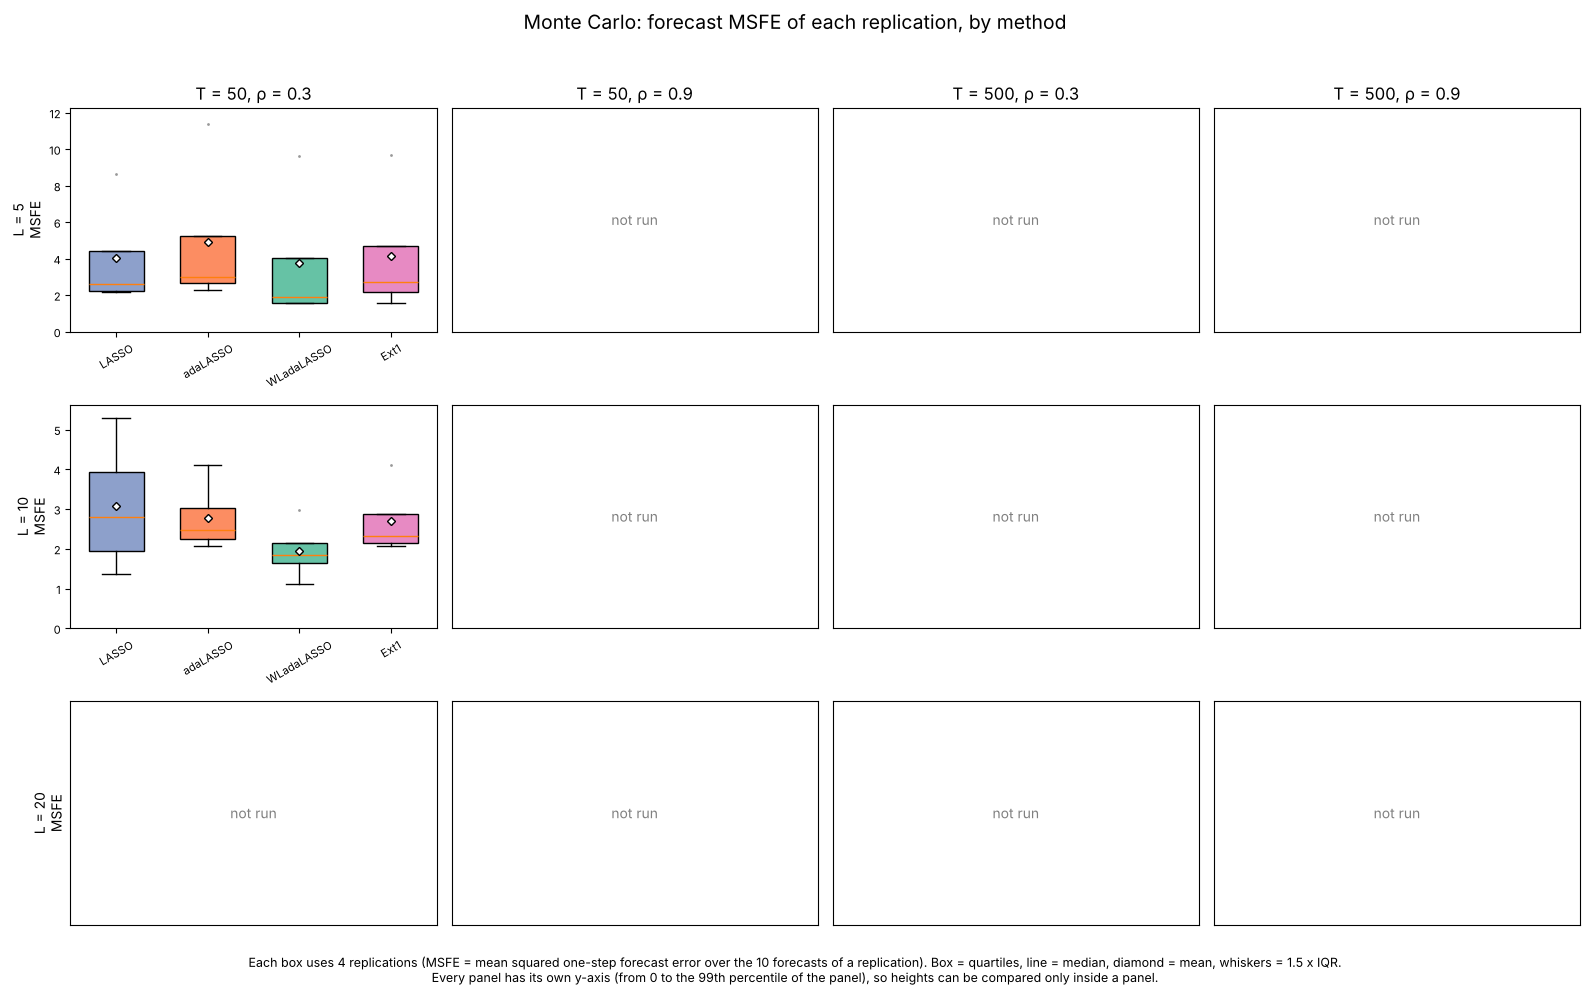

Figure saved as: results/monte_carlo/figures/quick_check_22091d85bb/mc_msfe_boxplots_standard_quick_check_22091d85bb.png (and .pdf)

Complete replication-level results were saved in: results/monte_carlo/standard/quick_check_22091d85bb
Forecast errors of every forecast are in forecast_errors.csv.gz in the same folder. The summaries above were saved in: results/monte_carlo/summaries/quick_check_22091d85bb


In [26]:
MC_DF = collect_finished(CKPT, MC_RUN_ID, SCENARIOS)
if len(MC_DF) == 0:
    print("No finished Monte Carlo replications yet. Run cell 9.1 first (RUN['monte_carlo'] = True).")
else:
    MC_PATHS = finish_mc_run(RESULTS, "standard", MC_RUN_ID, MC_DF, SCENARIOS, CFG["mc"], run_settings(), completion_status, mc_tables,
                             make_figure=MAKE_VISUALISATIONS, figure_if_incomplete=FIGURE_EVEN_IF_INCOMPLETE)
    MC_TABLES = mc_tables(MC_DF)
    for _name, _tab in MC_TABLES.items():
        print("\n" + _name)
        display(_tab.round(4))
    SUMMARY = summary_table(MC_DF)
    BOUND = boundary_table(MC_DF)
    save_csv(SUMMARY, os.path.join(MC_PATHS["summaries"], "summary_all_metrics.csv"))
    save_csv(BOUND, os.path.join(MC_PATHS["summaries"], "boundary_diagnostics_by_scenario.csv"))
    print("\nShare of fits with a tuning value on the edge of its grid (all scenarios together):")
    display(mc_boundary_summary(MC_DF).round(3))
    print("\nPlain counts from these results:")
    for _line in mc_findings(MC_DF):
        print(" -", _line)
    if MC_PATHS.get("fig_object") is not None:
        plt.show()
        plt.close(MC_PATHS["fig_object"])
        print("Figure saved as:", short_path(RESULTS, MC_PATHS["figure"]), "(and .pdf)")
    print("\nComplete replication-level results were saved in:", short_path(RESULTS, MC_PATHS["run_folder"]))
    print("Forecast errors of every forecast are in forecast_errors.csv.gz in the same folder. The summaries above were saved in:", short_path(RESULTS, MC_PATHS["summaries"]))

**What the output of 9.3 shows.** In this experiment we simulated the same data for all four methods and compared them. Each row of a table is one scenario (ρ, T, L).
* *MSFE* is the mean squared one-step forecast error of a replication (ten forecasts); the tables show its mean and median over replications. *MAE* is the mean absolute error.
* The ratio table divides each method's mean MSFE by that of adaLASSO: a value below 1 means a smaller average error than adaLASSO in that scenario.
* The selection table shows how well the true model was found. The true number of selected variables (NIV) is 10; FRVI/recall is the share of the 10 relevant variables that were selected; FIVE is the share of irrelevant variables that were dropped.
* The boundary table shows how often a tuning value (λ, α, κ, γ) ended at the edge of its grid; high shares would mean that the grid may be too narrow.

The tables describe the simulated data only. **We make no claim about which method is better before the numbers exist;** the statistical comparisons in section 14 test the differences.

**The figure (12 panels).** Rows are the lag count L = 5, 10, 20. Columns are (T = 50, ρ = 0.3), (T = 50, ρ = 0.9), (T = 500, ρ = 0.3), (T = 500, ρ = 0.9). Each panel has one box for each of LASSO, adaLASSO, WLadaLASSO and Ext1; the box shows the spread of the MSFE over the replications
(line = median, diamond = mean). **Each panel has its own y-axis** (0 up to the 99th percentile of that panel), because the error levels differ a lot between T = 50 and T = 500; compare heights only within a panel. The number of points above the axis is printed in the panel.

## 10. Equity-premium experiments  **[RUN] then [RESULTS]**

**Setup (documented; identical for all three data specifications).** Annual Goyal–Welch data 1927–2005; 14 predictors (d/p, d/y, e/p, d/e, svar, b/m, ntis, tbl, lty, ltr, tms, dfy, dfr, infl);
excess return = log(1+R) − log(1+Rfree); predictors are first-differenced after cutting the sample to 1927–2005 (the premium stays in levels — spec A, primary);
the forecast of year *t* uses the predictors of year *t−1* and only data before *t*; expanding window, refit every year; lag order ℓ ∈ {1..5} chosen by BIC (and ℓ = 1 reported separately);
benchmark = expanding historical mean; $R^2_{OS}$ and the one-sided modified Diebold–Mariano test (h = 1); evaluation starts 1955 / 1970 / 1985 (51 / 36 / 21 forecasts).

**Data specifications (kept separate, never mixed):**
`original_2005_index` — original 2005 release, documented Welch–Goyal Index-based premium · `current_crsp` — current file, CRSP_SPvw premium · `current_index` — current file, Index-based premium.

**Unresolved discrepancy (preserved).** In the earlier study none of these reproduced the published Table X (penalised rows ≈ 0 or negative versus +0.07…+0.47 in the paper; mean absolute gap ≈ 0.45).
We did **not** change transformations, benchmark or sample to approach the paper, and we do not claim the paper is wrong. The comparison below is descriptive.

**Which cells to run.** 10.1 loads and checks the data, 10.2 prints data diagnostics, 10.3 runs the experiment (needs `RUN["equity"] = True`), 10.4 shows and saves the results.
**Expected output of 10.4:** for each data version, a table of $R^2_{OS}$ with p-values, a comparison with the published Table X, and a short selection summary. The files are saved in `equity_premium/<data version>/<run id>/`.

### 10.1 Load the data and check it  **[SETUP]**

In [27]:
import pandas as pd, numpy as np
EQ_DATA = {}
for name, d in CFG["equity_datasets"].items():
    path = DATA.get(d["file"])
    if path is None or not DATA_OK.get(d["file"], False):
        print(f"[{name}] data file missing or failed validation ({d['file']}): this specification cannot be run; NO substitute data are used")
        continue
    df = load_goyal_welch(path, premium_source=d["premium_source"], **{k: CFG["equity_common"][k] for k in ("sheet", "log_premium", "start_year", "end_year", "diff_predictors")})
    EQ_DATA[name] = df
    print(f"[{name}] {d['description']}")
    print(f"    shape {df.shape}, years {df.index.min()}-{df.index.max()}, NaN {int(df.isna().sum().sum())}, dtypes ok: {all(df.dtypes == 'float64')}")

[original_2005_index] data file missing or failed validation (equity_premium/original_2005_vintage/PredictorData_2005_original.xls): this specification cannot be run; NO substitute data are used


[current_crsp] Current Goyal-Welch file (2026 download); premium from CRSP_SPvw
    shape (78, 15), years 1928-2005, NaN 0, dtypes ok: True
[current_index] Current Goyal-Welch file (same file); premium from Index and D12
    shape (78, 15), years 1928-2005, NaN 0, dtypes ok: True


/usr/local/lib/python3.13/site-packages/openpyxl/worksheet/header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")
/usr/local/lib/python3.13/site-packages/openpyxl/worksheet/header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")


### 10.2 Data diagnostics  **[RESULTS]**

In [28]:
for name, df in EQ_DATA.items():
    print(f"\n--- diagnostics: {name}")
    print(equity_diagnostics(df, CFG["equity_common"]["starts"], CFG["equity_common"]["Lmax"]).to_string(index=False))


--- diagnostics: current_crsp
                                                             check      value
                                                   first/last year  1928-2005
                                                    n observations         78
                                                    missing values          0
                                                  duplicated years          0
                                         years strictly increasing       True
                                       consecutive years (no gaps)       True
                                          forecasts for start 1955         51
                                          forecasts for start 1970         36
                                          forecasts for start 1985         21
leakage: training rows for first forecast end before forecast year       True
                      benchmark for first forecast uses only years 1928..1954
                             enou

### 10.3 Run (or resume) the experiment  **[RUN]**
Set `RUN['equity']` to `True` in section 8 first.

In [29]:
EQ_SPEC_KEY = "A_primary"                                   # A_primary | B_simple_premium | C_diff_premium | D_diff_premium_own_lags (see config.EQUITY_SPECS)
EQ_WHICH = ["original_2005_index", "current_crsp", "current_index"]      # data specifications to run (each has its own run id and folder)
EQ_RESULTS = {}

def equity_run_id(ds):
    return f"{PROFILE}_{ds}_{EQ_SPEC_KEY}_{config_id(dict(ds=CFG['equity_datasets'][ds], common=CFG['equity_common'], spec=CFG['equity_specs'][EQ_SPEC_KEY], grids=GRIDS, lam=LAM, v=CONFIG_VERSION))}"

if not RUN["equity"]:
    print("Skipped: set RUN['equity'] = True in section 8 to run (or resume) the equity-premium experiment for the data versions in EQ_WHICH.")
else:
    for ds in EQ_WHICH:
        if ds not in EQ_DATA:
            print(f"[{ds}] data not available -> skipped"); continue
        spec_cfg = dict(CFG["equity_common"], **CFG["equity_specs"][EQ_SPEC_KEY])
        df_ds = EQ_DATA[ds] if not CFG["equity_specs"][EQ_SPEC_KEY] else load_goyal_welch(
            DATA[CFG["equity_datasets"][ds]["file"]], premium_source=CFG["equity_datasets"][ds]["premium_source"],
            **{k: spec_cfg[k] for k in ("sheet", "log_premium", "start_year", "end_year", "diff_predictors")}, diff_target=spec_cfg.get("diff_target", False))
        res, info = run_equity(df_ds, CFG["equity_common"], CFG["equity_specs"][EQ_SPEC_KEY], GRIDS, LAM, CKPT, equity_run_id(ds), n_jobs=1)
        EQ_RESULTS[ds] = (results_to_frame(res), info)
        log_event(RESULTS, f"Equity premium finished: {ds} | {equity_run_id(ds)}")

[original_2005_index] data not available -> skipped
equity: fitting l = 1 models ...


equity: fitting free-l models (l = 1..Lmax by BIC) ...


Equity premium finished: current_crsp | quick_check_current_crsp_A_primary_a9f824fecd
equity: fitting l = 1 models ...


equity: fitting free-l models (l = 1..Lmax by BIC) ...


Equity premium finished: current_index | quick_check_current_index_A_primary_af33e98fd1


### 10.4 Show and save the results  **[RESULTS]**

In [30]:
# Show and save the results. After a restart, run the previous cell again (with RUN['equity'] = True): finished origins are loaded, not recomputed.
if not EQ_RESULTS:
    print("No equity results in this session yet. Run the previous cell with RUN['equity'] = True.")
for ds, (tab, info) in EQ_RESULTS.items():
    print(f"\n=== data version: {ds} | specification: {EQ_SPEC_KEY}")
    cmp = compare_with_paper(tab, PAPER_CSV)
    EQ_PATHS = finish_equity_run(RESULTS, ds, equity_run_id(ds), tab, info, cmp, run_settings(equity_spec=EQ_SPEC_KEY, data_version=ds))
    print("R2_OS (out-of-sample R-squared against the historical mean) and p-value of the modified Diebold-Mariano test, by start year of the evaluation:")
    display(equity_wide(tab).round(4))
    for _line in equity_findings(tab):
        print(" -", _line)
    print("\nOur results next to the published Table X (descriptive only):")
    display(cmp.round(4))
    print("mean absolute gap to the paper:", round(float(cmp['gap'].abs().mean()), 4))
    print("\nChosen lag order, number of selected variables and boundary shares (penalised models with free lag order):")
    display(selection_summary(info).round(3))
    print("Complete results were saved in:", short_path(RESULTS, EQ_PATHS["folder"]))


=== data version: current_crsp | specification: A_primary
R2_OS (out-of-sample R-squared against the historical mean) and p-value of the modified Diebold-Mariano test, by start year of the evaluation:


,1955: R2_OS,1955: p-value,1970: R2_OS,1970: p-value,1985: R2_OS,1985: p-value
model,,,,,,
d/p,-0.0488,0.8051,-0.0233,0.6384,-0.0228,0.6549
d/y,-0.0016,0.5265,0.0216,0.2314,-0.0341,0.7481
e/p,-0.0104,0.7850,-0.0133,0.8061,0.0017,0.4610
d/e,-0.0867,0.7815,-0.0721,0.6917,0.1299,0.2876
svar,-0.0004,0.5175,-0.0006,0.5280,-0.0114,0.8422
b/m,-0.0067,0.6881,-0.0031,0.5863,-0.0016,0.5501
ntis,-0.0137,0.8066,-0.0153,0.7706,-0.0383,0.9333
tbl,-0.0321,0.6159,-0.0668,0.6724,-0.2438,0.9124
lty,-0.0252,0.5718,-0.1201,0.7409,-0.1903,0.9358


 - Start 1955: 0 of 6 penalised models have a positive R2_OS; 0 have a p-value below 0.10 (R2_OS from -0.293 to -0.018).
 - Start 1970: 1 of 6 penalised models have a positive R2_OS; 0 have a p-value below 0.10 (R2_OS from -0.156 to 0.003).
 - Start 1985: 2 of 6 penalised models have a positive R2_OS; 0 have a p-value below 0.10 (R2_OS from -0.034 to 0.029).

Our results next to the published Table X (descriptive only):


,row,start,paper_R2,paper_p,our_R2,our_p,gap
0,Dividend price ratio,1955,-0.0538,0.5748,-0.0488,0.8051,0.0050
1,Dividend price ratio,1970,-0.0343,0.5367,-0.0233,0.6384,0.0110
2,Dividend price ratio,1985,-0.2707,0.7018,-0.0228,0.6549,0.2479
3,Dividend yield,1955,-0.0060,0.5076,-0.0016,0.5265,0.0044
4,Dividend yield,1970,-0.0195,0.5197,0.0216,0.2314,0.0411
5,Dividend yield,1985,0.0062,0.4949,-0.0341,0.7481,-0.0403
6,Earning price ratio,1955,-0.3001,0.7963,-0.0104,0.7850,0.2897
7,Earning price ratio,1970,-0.3820,0.7746,-0.0133,0.8061,0.3687
8,Earning price ratio,1985,-1.0106,0.8727,0.0017,0.4610,1.0123
9,Dividend payout ratio,1955,-0.0175,0.5218,-0.0867,0.7815,-0.0692


mean absolute gap to the paper: 0.2876

Chosen lag order, number of selected variables and boundary shares (penalised models with free lag order):


,mean lag order,mean number of selected variables,share of fits with lambda at the smallest grid value,share with alpha at upper bound,share with kappa at upper bound
method,,,,,
LASSO,1.412,0.765,0.0,0.0,0.00
adaLASSO,2.275,2.039,0.0,0.0,0.00
WLadaLASSO,2.333,2.059,0.0,0.0,0.00
Ext1,2.373,2.059,0.0,0.0,0.02


... (3 outputs left out)

,row,start,paper_R2,paper_p,our_R2,our_p,gap
0,Dividend price ratio,1955,-0.0538,0.5748,-0.0437,0.7918,0.0101
1,Dividend price ratio,1970,-0.0343,0.5367,-0.0195,0.6226,0.0148
2,Dividend price ratio,1985,-0.2707,0.7018,-0.0222,0.6583,0.2485
3,Dividend yield,1955,-0.0060,0.5076,-0.0004,0.5060,0.0056
4,Dividend yield,1970,-0.0195,0.5197,0.0235,0.2107,0.0430
5,Dividend yield,1985,0.0062,0.4949,-0.0319,0.7336,-0.0381
6,Earning price ratio,1955,-0.3001,0.7963,-0.0081,0.7230,0.2920
7,Earning price ratio,1970,-0.3820,0.7746,-0.0117,0.7735,0.3703
8,Earning price ratio,1985,-1.0106,0.8727,0.0019,0.4593,1.0125
9,Dividend payout ratio,1955,-0.0175,0.5218,-0.0732,0.7534,-0.0557


mean absolute gap to the paper: 0.2828

Chosen lag order, number of selected variables and boundary shares (penalised models with free lag order):


,mean lag order,mean number of selected variables,share of fits with lambda at the smallest grid value,share with alpha at upper bound,share with kappa at upper bound
method,,,,,
LASSO,1.667,1.255,0.0,0.0,0.0
adaLASSO,2.314,1.725,0.0,0.0,0.0
WLadaLASSO,2.353,1.725,0.0,0.0,0.0
Ext1,2.412,1.745,0.0,0.0,0.0


Complete results were saved in: results/equity_premium/current_index/quick_check_current_index_A_primary_af33e98fd1


**What the output of 10.4 shows.** We forecast the annual equity premium with an expanding window and compared each model with the historical mean using the out-of-sample $R^2_{OS}$ (positive = smaller squared error than the historical mean).
The p-value is from the one-sided modified Diebold–Mariano test of the null that the model is not better than the historical mean. The comparison table puts our numbers next to the published ones; the column `gap` is ours minus the paper's.
The earlier study found a large unexplained gap; we did not change the data treatment to reduce it. The three data versions are shown separately and never mixed. The counts under the table are plain counts, not conclusions.

## 11. FRED-MD experiments  **[RUN] then [RESULTS]**

Target: change in annualised monthly CPI inflation (CPIAUCSL); 121 transformed predictors plus the target's own lags (122 series; FRED-MD t-codes, outliers > 10 IQR removed with past-only statistics, series with > 5% missing dropped, gaps filled), L = 12 lags ⇒ 1,464 candidates;
60 one-step-ahead forecasts (Oct 2020 – Sep 2025), expanding window, **model refit at every origin**; benchmark **AR(BIC)** with p ∈ {0,…,12} chosen by BIC at each origin.
(In the earlier study no method beat AR(BIC); this run re-estimates everything with the new grids.)

**Profiles.** `standard` runs all 60 refits (the final result). `intermediate` runs only the first 20 refits and `quick_check` only 3; both are marked as pilot runs and saved under their own run id.

**Which cells to run.** 11.1 loads and checks the data, 11.2 runs the experiment (needs `RUN["fred_md"] = True`) and shows the results. **Expected output:** an accuracy table (RMSE, MAE, relative to AR(BIC), $R^2_{OS}$, p-values), paired tests between the methods, and the saved paths.

### 11.1 Load the data and check it  **[SETUP]**

In [31]:
FRED_PATH = DATA.get(CFG["fred"]["file"])
if FRED_PATH is not None and DATA_OK.get(CFG["fred"]["file"], False):
    FRED_X, FRED_LEVELS, FRED_TCODES = load_fred_md(FRED_PATH, start=CFG["fred"]["start"], end=CFG["fred"]["end"],
                                                         max_missing=CFG["fred"]["max_missing"], outlier_iqr=CFG["fred"]["outlier_iqr"])
    FRED_DF, FRED_PI = build_panel(FRED_LEVELS, FRED_X, CFG["fred"]["target"])
    print(f"FRED-MD transformed panel: {FRED_X.shape[0]} months x {FRED_X.shape[1]} series ({FRED_X.index.min():%Y-%m} to {FRED_X.index.max():%Y-%m})")
    print(f"forecasting panel (target + {FRED_DF.shape[1]-1} predictors): {FRED_DF.shape}; candidates = {FRED_DF.shape[1]} x L = {FRED_DF.shape[1]*CFG['fred']['L']}")
    print("dates increasing:", FRED_DF.index.is_monotonic_increasing, "| duplicates:", FRED_DF.index.has_duplicates, "| NaN:", int(FRED_DF.isna().sum().sum()))
    print("forecast origins:", FRED_DF.index[-CFG["fred"]["n_test"]].strftime("%Y-%m"), "to", FRED_DF.index[-1].strftime("%Y-%m"))
else:
    FRED_X = FRED_LEVELS = None
    print("FRED-MD file missing or failed validation; the FRED-MD experiment cannot run (no substitute data are used).")

FRED-MD transformed panel: 787 months x 122 series (1960-03 to 2025-09)
forecasting panel (target + 121 predictors): (787, 122); candidates = 122 x L = 1464
dates increasing: True | duplicates: False | NaN: 0
forecast origins: 2020-10 to 2025-09


### 11.2 Run (or resume) the experiment and show the results  **[RUN]**
Set `RUN['fred_md']` to `True` in section 8 first.

In [32]:
FRED_RUN_ID = f"{PROFILE}_{config_id(dict(fred=CFG['fred'], grids=GRIDS, lam=LAM, v=CONFIG_VERSION))}"
FRED_OUT = None
if not RUN["fred_md"]:
    print("Skipped: set RUN['fred_md'] = True in section 8 to run (or resume) the FRED-MD experiment. Run id:", FRED_RUN_ID)
else:
    pilot = {"quick_check": 3, "intermediate": 20}.get(PROFILE)   # quick_check: only 3 refits; intermediate: first 20 of the 60 refits (not a final result)
    log_event(RESULTS, f"FRED-MD started or resumed: {FRED_RUN_ID}")
    FRED_OUT = run_fred(FRED_LEVELS, FRED_X, CFG["fred"], GRIDS, LAM, CKPT, FRED_RUN_ID, n_jobs=CFG["fred"]["n_jobs"], n_origins=pilot)
    FRED_ACC, FRED_PAIR_TESTS = summarise_fred(FRED_OUT)
    FRED_PATHS = finish_fred_run(RESULTS, FRED_RUN_ID, FRED_OUT, FRED_ACC, FRED_PAIR_TESTS, list(FRED_DF.columns), CFG["fred"]["L"], FRED_DF.index,
                                 run_settings(fred=CFG["fred"], pilot_origins=pilot), complete=pilot is None)
    log_event(RESULTS, f"FRED-MD finished: {FRED_RUN_ID}")
    print("Forecast accuracy. relRMSE is the RMSE divided by the RMSE of AR(BIC); R2_OS_vs_AR is the out-of-sample R-squared against AR(BIC); p_MSE and p_MAE are one-sided modified Diebold-Mariano p-values against AR(BIC).")
    display(FRED_ACC.round(4))
    print("Paired comparisons between methods (MSE_ratio below 1 = the first method has the smaller MSE):")
    display(FRED_PAIR_TESTS.round(4))
    for _line in fred_findings(FRED_ACC):
        print(" -", _line)
    print("AR(BIC) orders chosen at the origins (order: number of origins):", dict(zip(*np.unique(FRED_OUT["ar_orders"], return_counts=True))))
    print("Complete results (forecasts, selected variables at each refit, tables) were saved in:", short_path(RESULTS, FRED_PATHS["folder"]))
    if pilot is not None:
        print("NOTE: this is a short test with", pilot, "refits (profile " + PROFILE + "), not a final result.")

FRED-MD started or resumed: quick_check_fa131391da


FRED-MD finished: quick_check_fa131391da
Forecast accuracy. relRMSE is the RMSE divided by the RMSE of AR(BIC); R2_OS_vs_AR is the out-of-sample R-squared against AR(BIC); p_MSE and p_MAE are one-sided modified Diebold-Mariano p-values against AR(BIC).


,RMSE,MAE,relRMSE,relMAE,p_MSE,p_MAE,R2_OS_vs_AR
model,,,,,,,
AR(BIC),2.4267,1.9754,1.0000,1.0000,NaN,NaN,NaN
lasso,1.8221,1.5960,0.7508,0.8079,0.3268,0.3937,0.4362
adalasso,2.0806,1.9214,0.8574,0.9726,0.4047,0.4857,0.2649
wladalasso,1.7893,1.5459,0.7373,0.7825,0.3393,0.3923,0.4563
ext1,2.2354,2.0236,0.9212,1.0244,0.4528,0.5113,0.1514


Paired comparisons between methods (MSE_ratio below 1 = the first method has the smaller MSE):


,better,than,MSE_ratio,p_MSE,p_MAE
0,ext1,wladalasso,1.5608,0.8760,0.9416
1,wladalasso,adalasso,0.7396,0.0163,0.0186
2,ext1,adalasso,1.1544,0.7168,0.6826
3,adalasso,lasso,1.3038,0.8409,0.8830


 - Methods with a positive out-of-sample R2 against AR(BIC): LASSO, adaLASSO, WLadaLASSO, Ext1.
 - R2_OS against AR(BIC): LASSO 0.436, adaLASSO 0.265, WLadaLASSO 0.456, Ext1 0.151.
 - Methods whose MSE is significantly smaller than AR(BIC) at the 10% level (one-sided modified Diebold-Mariano): none.
AR(BIC) orders chosen at the origins (order: number of origins): {np.int64(11): np.int64(3)}
Complete results (forecasts, selected variables at each refit, tables) were saved in: results/fred_md/summaries/quick_check_fa131391da
NOTE: this is a short test with 3 refits (profile quick_check), not a final result.


**What the output shows.** In this experiment we forecast the monthly change in CPI inflation and compared the four methods with an AR(BIC) benchmark over the evaluation period. The accuracy table gives the errors; `R2_OS_vs_AR` is positive when a method has a smaller squared error than the AR benchmark.
The saved file `selected_variables_per_refit.csv` lists which series and lags each method selected at every refit. The numbers belong to this run only; compare them with the earlier study only descriptively.

## 12. The five final experiments and how each is run  **[RESULTS]**

| # | Experiment | Where / how |
|---|---|---|
| 1 | Main Monte Carlo, 12 scenarios, 1,000 replications, γ = 1 | `PROFILE = "standard"`, `RUN["monte_carlo"] = True`, section 9 |
| 2 | γ-BIC Monte Carlo, 300 replications (BIC also chooses γ) | `PROFILE = "full"`, `RUN["robustness_gamma"] = True`, section 13 (separate run id and folder) |
| 3 | Main equity premium, three data versions, γ = 1 | `RUN["equity"] = True`, section 10 |
| 4 | γ-BIC equity premium | `PROFILE = "full"`, `RUN["equity"] = True`, section 10 (the `*_g` methods) |
| 5 | FRED-MD monthly inflation, 60 refits | `RUN["fred_md"] = True`, section 11 (`PROFILE = "standard"`) |

The fixed-γ and γ-BIC results are kept in separate run folders and are never mixed. Every run keeps its checkpoints (atomic writes, one file per chunk or forecast origin, run ids from a hash of the settings, resume after disconnection, overwrite protection, damaged checkpoint files set aside).


## 13. Robustness experiments  **[RUN] then [RESULTS]**
The γ-BIC Monte Carlo is an **independent run with its own run id and its own folder**; it never replaces a main result.
* **γ-BIC Monte Carlo (final experiment ii, 300 replications):** `PROFILE = "full"` and `RUN["robustness_gamma"] = True`; BIC also chooses γ (the `*_g` methods). Saved in `monte_carlo/gamma_robustness/<run id>/`.
* **Data versions / premium variants:** section 10 runs the three equity data versions side by side (with `PROFILE = "full"` also the γ-BIC variants, final experiment iv); `EQ_SPEC_KEY` selects the premium variants B/C/D.

**Expected output of each cell:** a status table, then the mean MSFE by scenario and method, the saved paths and (if `MAKE_VISUALISATIONS`) the same 12-panel figure for that run.

In [33]:
if not RUN["robustness_gamma"]:
    print("Skipped: set PROFILE = 'full' and RUN['robustness_gamma'] = True in section 8 to run the gamma cross-grid Monte Carlo.")
else:
    assert PROFILE == "full", "the gamma robustness run is defined for PROFILE = 'full'"
    ROB_RUN_ID = MC_RUN_ID + "_gamma_cross"
    update_run_metadata(os.path.join(RESULTS, "monte_carlo", "gamma_robustness", ROB_RUN_ID), "monte_carlo/gamma_robustness", ROB_RUN_ID, "running (or interrupted)", run_settings())
    log_event(RESULTS, f"Monte Carlo (gamma robustness) started or resumed: {ROB_RUN_ID}")
    ROB_DF, ROB_STATUS = run_all(CKPT, ROB_RUN_ID, CFG, GRIDS, LAM, SCENARIOS, n_jobs=CFG["mc"]["n_jobs"])
    display(ROB_STATUS)
    ROB_PATHS = finish_mc_run(RESULTS, "gamma_robustness", ROB_RUN_ID, ROB_DF, SCENARIOS, CFG["mc"], run_settings(), completion_status, mc_tables,
                              make_figure=MAKE_VISUALISATIONS, figure_if_incomplete=FIGURE_EVEN_IF_INCOMPLETE)
    if len(ROB_DF):
        print("Mean MSFE by scenario; the *_g methods let BIC choose gamma as well:")
        display(ROB_DF.groupby(["rho", "T", "L", "variant"])["fc_mse"].mean().unstack("variant").round(4))
        if ROB_PATHS.get("fig_object") is not None:
            plt.show()
            plt.close(ROB_PATHS["fig_object"])
        print("Complete replication-level results were saved in:", short_path(RESULTS, ROB_PATHS["run_folder"]))

Skipped: set PROFILE = 'full' and RUN['robustness_gamma'] = True in section 8 to run the gamma cross-grid Monte Carlo.


## 14. Statistical comparisons of the methods  **[RESULTS]**
In the Monte Carlo we compare two methods on the **same simulated data** in every replication (a paired comparison). For each scenario we calculated the mean difference of the loss (first method minus second method; **negative = the first method has the smaller loss**), a normal and a bootstrap 95% interval,
a paired t-test, a Wilcoxon signed-rank test, and the share of replications in which the first method has the smaller loss.
For the empirical studies, the one-sided modified Diebold–Mariano test (h = 1) is shown inside sections 10–12. **No adjustment for multiple testing is made**; the p-values are descriptive.
**Expected output:** a table for the MSFE (the table for the MAE is saved in the file). The complete table is saved in `monte_carlo/summaries/<run id>/paired_tests_all_metrics.csv`.

In [34]:
if len(MC_DF):
    COMP = comparisons(MC_DF, [("wladalasso", "adalasso"), ("ext1", "adalasso"), ("ext1", "wladalasso"), ("adalasso", "lasso"), ("wladalasso", "lasso")])
    COMP_SHOWN = mc_paired_tests(MC_DF, comparisons)
    _dir = os.path.join(RESULTS, "monte_carlo", "summaries", MC_RUN_ID)
    save_csv(COMP, os.path.join(_dir, "paired_tests_raw_output.csv"))
    save_csv(COMP_SHOWN, os.path.join(_dir, "paired_tests_all_metrics.csv"))
    print("Paired comparisons of the MSFE (first method minus second method):")
    display(COMP_SHOWN[COMP_SHOWN.metric == "fc_mse"].drop(columns="metric").round(4))
    print("Complete tables (MSFE and MAE) were saved in:", short_path(RESULTS, _dir))
else:
    print("No finished Monte Carlo replications yet (run section 9 first).")

Paired comparisons of the MSFE (first method minus second method):


,rho,T,L,comparison,n,mean difference,95% CI low,95% CI high,bootstrap 95% CI low,bootstrap 95% CI high,p-value (t-test),p-value (Wilcoxon),share of replications where the first method is better
0,0.3,50,5,WLadaLASSO minus adaLASSO,4,-1.1744,-1.9213,-0.4276,-1.6791,-0.4552,0.0540,0.125,1.00
2,0.3,50,5,Ext1 minus adaLASSO,4,-0.7544,-1.4413,-0.0675,-1.4267,-0.2646,0.1204,0.125,1.00
4,0.3,50,5,Ext1 minus WLadaLASSO,4,0.4200,-0.4721,1.3121,-0.2993,1.1394,0.4242,0.375,0.25
6,0.3,50,5,WLadaLASSO minus LASSO,4,-0.2714,-1.3086,0.7658,-1.0992,0.6011,0.6435,0.875,0.50
8,0.3,50,5,adaLASSO minus LASSO,4,0.9031,-0.4118,2.2179,-0.0538,2.1097,0.2709,0.375,0.25
10,0.3,50,10,WLadaLASSO minus adaLASSO,4,-0.8412,-1.1195,-0.5630,-1.0544,-0.5988,0.0096,0.125,1.00
12,0.3,50,10,Ext1 minus adaLASSO,4,-0.0758,-0.2248,0.0732,-0.2023,0.0507,0.3923,0.500,0.50
14,0.3,50,10,Ext1 minus WLadaLASSO,4,0.7654,0.3602,1.1707,0.4276,1.1033,0.0342,0.125,0.00
16,0.3,50,10,WLadaLASSO minus LASSO,4,-1.1248,-2.2713,0.0218,-1.9987,-0.0720,0.1502,0.250,0.75
18,0.3,50,10,adaLASSO minus LASSO,4,-0.2835,-1.1901,0.6231,-0.9959,0.4821,0.5832,0.625,0.75


Complete tables (MSFE and MAE) were saved in: results/monte_carlo/summaries/quick_check_22091d85bb


**How to read the table.** A negative `mean difference` means that the first method had the smaller average MSFE. If both confidence intervals exclude 0 and the p-values are small, the data speak against an equal MSFE in that scenario;
`share of replications where the first method is better` shows how consistent the difference is. We performed many tests (many scenarios and pairs), so a few small p-values are expected by chance.

## 15. Figures  **[RESULTS]**
The main figure is the 12-panel boxplot of the Monte Carlo MSFE (section 9.3, saved in `monte_carlo/figures/<run id>/`). It is drawn only if `MAKE_VISUALISATIONS = True`; setting it to `False` skips all plotting and nothing else changes.
Because our supervisor prefers few graphs, the older single-panel figure (mean MSFE divided by that of adaLASSO) is now optional: set `SHOW_RATIO_FIGURE = True` below. **Expected output:** the list of saved figure files and, if requested, the ratio figure.

In [35]:
SHOW_RATIO_FIGURE = False        # True: also draw the older figure "mean MSFE relative to adaLASSO"
if not MAKE_VISUALISATIONS:
    print("Skipped: MAKE_VISUALISATIONS is False in section 8.")
elif len(MC_DF) == 0:
    print("No finished Monte Carlo replications yet (run section 9 first).")
else:
    _figdir = os.path.join(RESULTS, "monte_carlo", "figures", MC_RUN_ID)
    _files = sorted(glob.glob(os.path.join(_figdir, "*")))
    print("saved figure files:", [short_path(RESULTS, f) for f in _files] or "none yet (the boxplot is drawn when all replications are finished)")
    if SHOW_RATIO_FIGURE:
        _fig = forecast_ratio_figure(MC_DF, path=os.path.join(_figdir, f"fig_msfe_ratio_{MC_RUN_ID}.png"))
        plt.show()
        print("saved:", short_path(RESULTS, os.path.join(_figdir, f"fig_msfe_ratio_{MC_RUN_ID}.png")))

saved figure files: ['results/monte_carlo/figures/quick_check_22091d85bb/mc_msfe_boxplots_standard_quick_check_22091d85bb.pdf', 'results/monte_carlo/figures/quick_check_22091d85bb/mc_msfe_boxplots_standard_quick_check_22091d85bb.png']


## 16. Results summary and export  **[RESULTS]**
We list what is on disk (finished runs only), write a summary and the reproducibility information into the time-stamped folder `consolidated/<time stamp>/` (never overwritten), and make a ZIP file of the results folder that Colab offers for download.
By default the ZIP does not contain `checkpoints/` (they are large and only needed for resuming); set `INCLUDE_CHECKPOINTS_IN_ZIP = True` to include them. **Expected output:** the list of runs, the run registry, and the ZIP path.

In [36]:
CONS = os.path.join(RESULTS, "consolidated", RUN_STAMP)
os.makedirs(CONS, exist_ok=False)
found = {}
for exp in ("monte_carlo", "equity_premium", "fred_md"):
    base = os.path.join(RESULTS, exp)
    found[exp] = sorted(os.path.relpath(r, RESULTS) for r, _, fs in os.walk(base) if "run_metadata.json" in fs) if os.path.isdir(base) else []
print(json.dumps(found, indent=2))
_reg = os.path.join(RESULTS, "run_registry.csv")
if os.path.exists(_reg):
    print("\nRun registry (every run started or finished):")
    display(pd.read_csv(_reg))
MC_DF = collect_finished(CKPT, MC_RUN_ID, SCENARIOS)
if len(MC_DF):
    status = completion_status(MC_DF, CFG["mc"], SCENARIOS)
    display(status)
    save_table(status, CONS, "monte_carlo_completion")
    save_table(summary_table(MC_DF), CONS, "monte_carlo_summary")
    save_table(boundary_table(MC_DF), CONS, "monte_carlo_boundary_diagnostics")
write_json_once(CONS, "reproducibility", dict(env=reproducibility_info(), profile=PROFILE, config=CFG, grids=GRIDS, lam=LAM,
                                              run_ids=dict(mc=MC_RUN_ID, fred=FRED_RUN_ID), found=found))
print("summary folder:", short_path(RESULTS, CONS))

{
  "monte_carlo": [
    "monte_carlo/standard/quick_check_22091d85bb"
  ],
  "equity_premium": [
    "equity_premium/current_crsp/quick_check_current_crsp_A_primary_a9f824fecd",
    "equity_premium/current_index/quick_check_current_index_A_primary_af33e98fd1"
  ],
  "fred_md": [
    "fred_md/summaries/quick_check_fa131391da"
  ]
}

Run registry (every run started or finished):


,time,experiment,run_id,status,folder
0,2026-11-15 12:27:26,monte_carlo/standard,quick_check_22091d85bb,completed,monte_carlo/standard/quick_check_22091d85bb
1,2026-11-15 12:28:30,equity_premium/current_crsp,quick_check_current_crsp_A_primary_a9f824fecd,completed,equity_premium/current_crsp/quick_check_curren...
2,2026-11-15 12:28:30,equity_premium/current_index,quick_check_current_index_A_primary_af33e98fd1,completed,equity_premium/current_index/quick_check_curre...
3,2026-11-15 12:29:02,fred_md,quick_check_fa131391da,pilot run (only some origins),fred_md/summaries/quick_check_fa131391da


,rho,T,L,reps_done,reps_target,complete
0,0.3,50,5,4,4,True
1,0.3,50,10,4,4,True


summary folder: results/consolidated/20261115_122723


In [37]:
INCLUDE_CHECKPOINTS_IN_ZIP = False
ARCHIVE = os.path.join(WORK, f"WLadaLASSO_results_{RUN_STAMP}.zip")
with zipfile.ZipFile(ARCHIVE, "w", zipfile.ZIP_DEFLATED) as _z:
    for _r, _ds, _fs in os.walk(RESULTS):
        if not INCLUDE_CHECKPOINTS_IN_ZIP and os.path.relpath(_r, RESULTS).split(os.sep)[0] == "checkpoints":
            continue
        for _f in _fs:
            _z.write(os.path.join(_r, _f), os.path.relpath(os.path.join(_r, _f), os.path.dirname(RESULTS)))
print("results archive:", ARCHIVE, f"({os.path.getsize(ARCHIVE):,} bytes)")
if IN_COLAB:
    from google.colab import files
    files.download(ARCHIVE)
if not USE_DRIVE:
    print("Reminder: without Google Drive the results exist only until the runtime is recycled. Keep the downloaded ZIP.")

results archive: /home/claude/w/nbrun/wlada_work/WLadaLASSO_results_20261115_122723.zip (170,513 bytes)
Reminder: without Google Drive the results exist only until the runtime is recycled. Keep the downloaded ZIP.


### Known limitations
* This updated notebook was checked statically only (syntax, undefined names, leftovers); it was not executed end to end. Run the unit tests in section 7 and the `quick_check` profile first.
* Equity premium: the gap to the published Table X is unresolved.
* The tests are not adjusted for multiple comparisons; the boundary diagnostics are reported but not acted upon.